# Calibration and Statistical Analysis of Synthetic Saudi Diabetes Data

## Project Overview
This notebook evaluates a synthetic Saudi diabetes dataset generated using AI-assisted methods and assumptions informed by published studies.

## Objectives
- Assess data quality and internal consistency.
- Summarize demographic and clinical characteristics.
- Compare synthetic distributions with published reference statistics.
- Conduct appropriate statistical tests.
- Evaluate sensitivity to generation assumptions.

## Important Note
The dataset contains synthetic records, not real patients. Statistical findings describe the generated data and do not establish clinical relationships in the Saudi population.

In [1]:
from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from scipy import stats
from statsmodels.stats.proportion import proportion_confint
from statsmodels.stats.multitest import multipletests
from statsmodels.stats.contingency_tables import Table2x2
import statsmodels.api as sm
import statsmodels.formula.api as smf

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)
pd.set_option("display.float_format", "{:.4f}".format)

sns.set_theme(style="whitegrid")

print("Libraries imported successfully.")

Libraries imported successfully.


## Load The Generated Dataset

In [2]:
from pathlib import Path
import pandas as pd

DATA_PATH = Path(
    r"C:\Users\Admin\OneDrive\Documents\Diabetes_Analysis\data\synthetic_saudi_diabetes_central.csv"
)

if not DATA_PATH.exists():
    raise FileNotFoundError(f"Dataset not found: {r"C:\Users\Admin\OneDrive\Documents\Diabetes_Analysis\data\synthetic_saudi_diabetes_central.csv"}")

data = pd.read_csv(DATA_PATH)

print("Dataset loaded successfully.")
print("Dataset shape:", data.shape)
print("Number of records:", len(data))
print("Columns:", data.columns.tolist())

display(data.head())

Dataset loaded successfully.
Dataset shape: (10000, 19)
Number of records: 10000
Columns: ['id', 'sex', 'age', 'age_group', 'bmi', 'bmi_category', 'family_history', 'diabetes_status', 'diabetes_type', 'care_cascade', 'hba1c', 'fasting_glucose_mmol', 'hypertension', 'hypercholesterolemia', 'pregnant', 'gdm', 'scenario', 'scenario_label', 'synthetic']


,id,sex,age,age_group,bmi,bmi_category,family_history,diabetes_status,diabetes_type,care_cascade,hba1c,fasting_glucose_mmol,hypertension,hypercholesterolemia,pregnant,gdm,scenario,scenario_label,synthetic
0,SYN000000,F,35,35-44,44.5000,morbid,1,normal,none,none,5.3700,5.3000,0,0,0,0,central,Central prevalence scenario,True
1,SYN000001,M,58,55-64,29.1000,overweight,0,prediabetes,none,none,6.3300,6.6000,0,0,0,0,central,Central prevalence scenario,True
2,SYN000002,F,41,35-44,23.3000,normal,1,normal,none,none,5.3200,6.1000,0,0,0,0,central,Central prevalence scenario,True
3,SYN000003,F,28,25-34,22.7000,normal,0,normal,none,none,4.8500,5.1000,0,0,0,0,central,Central prevalence scenario,True
4,SYN000004,M,22,15-24,18.3000,underweight,0,prediabetes,none,none,6.0800,6.0000,0,0,0,0,central,Central prevalence scenario,True


## Inspect Dataset Structure

In [3]:
print("Column names:")
print(data.columns.tolist())

print("\nData types:")
display(data.dtypes.to_frame("Data Type"))

print("\nDataset information:")
data.info()

print("\nNumerical summary:")
display(data.describe(include="number").T)

print("\nCategorical summary:")
display(data.describe(include="object").T)

Column names:
['id', 'sex', 'age', 'age_group', 'bmi', 'bmi_category', 'family_history', 'diabetes_status', 'diabetes_type', 'care_cascade', 'hba1c', 'fasting_glucose_mmol', 'hypertension', 'hypercholesterolemia', 'pregnant', 'gdm', 'scenario', 'scenario_label', 'synthetic']

Data types:


,Data Type
id,str
sex,str
age,int64
age_group,str
bmi,float64
bmi_category,str
family_history,int64
diabetes_status,str
diabetes_type,str
care_cascade,str



Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 19 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   id                    10000 non-null  str    
 1   sex                   10000 non-null  str    
 2   age                   10000 non-null  int64  
 3   age_group             10000 non-null  str    
 4   bmi                   10000 non-null  float64
 5   bmi_category          10000 non-null  str    
 6   family_history        10000 non-null  int64  
 7   diabetes_status       10000 non-null  str    
 8   diabetes_type         10000 non-null  str    
 9   care_cascade          10000 non-null  str    
 10  hba1c                 10000 non-null  float64
 11  fasting_glucose_mmol  10000 non-null  float64
 12  hypertension          10000 non-null  int64  
 13  hypercholesterolemia  10000 non-null  int64  
 14  pregnant              10000 non-null  int64  
 15  gdm      

,count,mean,std,min,25%,50%,75%,max
age,10000.0000,35.2672,15.6573,15.0000,23.0000,32.0000,44.0000,85.0000
bmi,10000.0000,27.2614,6.7968,15.0000,21.9000,26.5000,31.5000,58.6000
family_history,10000.0000,0.3552,0.4786,0.0000,0.0000,0.0000,1.0000,1.0000
hba1c,10000.0000,5.7957,1.1201,4.5000,5.1500,5.4000,5.9500,11.6900
fasting_glucose_mmol,10000.0000,6.0762,1.8939,3.3000,4.9000,5.6000,6.5000,16.6000
hypertension,10000.0000,0.1466,0.3537,0.0000,0.0000,0.0000,0.0000,1.0000
hypercholesterolemia,10000.0000,0.0954,0.2938,0.0000,0.0000,0.0000,0.0000,1.0000
pregnant,10000.0000,0.0238,0.1524,0.0000,0.0000,0.0000,0.0000,1.0000
gdm,10000.0000,0.0023,0.0479,0.0000,0.0000,0.0000,0.0000,1.0000



Categorical summary:


C:\Users\Admin\AppData\Local\Temp\ipykernel_22628\2688390557.py:14: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  display(data.describe(include="object").T)


,count,unique,top,freq
id,10000,10000,SYN000000,1
sex,10000,2,M,5001
age_group,10000,6,15-24,2948
bmi_category,10000,5,normal,3372
diabetes_status,10000,3,normal,7073
diabetes_type,10000,3,none,8241
care_cascade,10000,5,none,8241
scenario,10000,1,central,10000
scenario_label,10000,1,Central prevalence scenario,10000


## Verify Expected Columns

In [4]:
expected_columns = [
    "id",
    "sex",
    "age",
    "age_group",
    "bmi",
    "bmi_category",
    "family_history",
    "diabetes_status",
    "diabetes_type",
    "care_cascade",
    "hba1c"
]

missing_columns = [
    col for col in expected_columns
    if col not in data.columns
]

if missing_columns:
    print("Expected columns not found:")
    print(missing_columns)
else:
    print("All expected columns are present.")

print("\nActual columns:")
print(data.columns.tolist())

All expected columns are present.

Actual columns:
['id', 'sex', 'age', 'age_group', 'bmi', 'bmi_category', 'family_history', 'diabetes_status', 'diabetes_type', 'care_cascade', 'hba1c', 'fasting_glucose_mmol', 'hypertension', 'hypercholesterolemia', 'pregnant', 'gdm', 'scenario', 'scenario_label', 'synthetic']


## Data  Quality Checks

Missing Values

In [5]:
missing_summary = pd.DataFrame({
    "Missing_Count": data.isna().sum(),
    "Missing_Percentage": data.isna().mean() * 100
}).sort_values("Missing_Percentage", ascending=False)

display(missing_summary)

,Missing_Count,Missing_Percentage
id,0,0.0000
sex,0,0.0000
age,0,0.0000
age_group,0,0.0000
bmi,0,0.0000
bmi_category,0,0.0000
family_history,0,0.0000
diabetes_status,0,0.0000
diabetes_type,0,0.0000
care_cascade,0,0.0000


Duplicate Records

In [6]:
print("Duplicate rows:", data.duplicated().sum())

if "id" in data.columns:
    print("Duplicate IDs:", data["id"].duplicated().sum())

Duplicate rows: 0
Duplicate IDs: 0


Validate Numeric Ranges

In [7]:
numeric_ranges = {
    "age": (15, 85),
    "bmi": (10, 80),
    "hba1c": (3, 20)
}

for col, (lower, upper) in numeric_ranges.items():
    if col not in data.columns:
        continue

    values = pd.to_numeric(data[col], errors="coerce")

    invalid = values.notna() & (
        (values < lower) | (values > upper)
    )

    print(
        f"{col}: {invalid.sum()} values outside "
        f"the screening range [{lower}, {upper}]"
    )

age: 0 values outside the screening range [15, 85]
bmi: 0 values outside the screening range [10, 80]
hba1c: 0 values outside the screening range [3, 20]


##  Descriptive Statistical Analysis

Numerical Summary Statistics

In [8]:
numeric_cols = data.select_dtypes(include="number").columns.tolist()

summary_stats = data[numeric_cols].describe().T

summary_stats["median"] = data[numeric_cols].median()
summary_stats["variance"] = data[numeric_cols].var()

display(summary_stats.round(3))

,count,mean,std,min,25%,50%,75%,max,median,variance
age,10000.0000,35.2670,15.6570,15.0000,23.0000,32.0000,44.0000,85.0000,32.0000,245.1500
bmi,10000.0000,27.2610,6.7970,15.0000,21.9000,26.5000,31.5000,58.6000,26.5000,46.1960
family_history,10000.0000,0.3550,0.4790,0.0000,0.0000,0.0000,1.0000,1.0000,0.0000,0.2290
hba1c,10000.0000,5.7960,1.1200,4.5000,5.1500,5.4000,5.9500,11.6900,5.4000,1.2550
fasting_glucose_mmol,10000.0000,6.0760,1.8940,3.3000,4.9000,5.6000,6.5000,16.6000,5.6000,3.5870
hypertension,10000.0000,0.1470,0.3540,0.0000,0.0000,0.0000,0.0000,1.0000,0.0000,0.1250
hypercholesterolemia,10000.0000,0.0950,0.2940,0.0000,0.0000,0.0000,0.0000,1.0000,0.0000,0.0860
pregnant,10000.0000,0.0240,0.1520,0.0000,0.0000,0.0000,0.0000,1.0000,0.0000,0.0230
gdm,10000.0000,0.0020,0.0480,0.0000,0.0000,0.0000,0.0000,1.0000,0.0000,0.0020


Categorical Distributions

In [9]:
categorical_cols = [
    col for col in [
        "sex",
        "age_group",
        "bmi_category",
        "family_history",
        "diabetes_status",
        "diabetes_type",
        "care_cascade"
    ]
    if col in data.columns
]

for col in categorical_cols:
    print(f"\n--- {col} ---")

    result = pd.DataFrame({
        "Count": data[col].value_counts(dropna=False),
        "Percentage": data[col].value_counts(
            normalize=True, dropna=False
        ) * 100
    })

    display(result.round(2))


--- sex ---


,Count,Percentage
sex,,
M,5001,50.0100
F,4999,49.9900



--- age_group ---


,Count,Percentage
age_group,,
15-24,2948,29.4800
25-34,2682,26.8200
35-44,1946,19.4600
45-54,1165,11.6500
55-64,725,7.2500
65+,534,5.3400



--- bmi_category ---


,Count,Percentage
bmi_category,,
normal,3372,33.7200
overweight,2996,29.9600
obese,2568,25.6800
underweight,713,7.1300
morbid,351,3.5100


... (4 outputs left out)


--- diabetes_type ---


,Count,Percentage
diabetes_type,,
none,8241,82.4100
T2,1731,17.3100
T1,28,0.2800



--- care_cascade ---


,Count,Percentage
care_cascade,,
none,8241,82.4100
undiagnosed,1011,10.1100
treated_uncontrolled,371,3.7100
treated_controlled,282,2.8200
untreated,95,0.9500


## Overall Diabetes Prevalence

In [10]:
print(data["diabetes_status"].value_counts(dropna=False))

diabetes_status
normal         7073
diabetes       1759
prediabetes    1168
Name: count, dtype: int64


In [11]:
DIABETES_LABEL = "diabetes"

is_diabetic = (
    data["diabetes_status"]
    .astype(str)
    .str.strip()
    .str.lower()
    .eq(DIABETES_LABEL.lower())
)

n = len(data)
cases = int(is_diabetic.sum())
prevalence = cases / n

ci_low, ci_high = proportion_confint(
    count=cases,
    nobs=n,
    alpha=0.05,
    method="wilson"
)

print(f"Total records: {n:,}")
print(f"Diabetes cases: {cases:,}")
print(f"Synthetic diabetes prevalence: {prevalence:.2%}")
print(f"95% Wilson CI: {ci_low:.2%}–{ci_high:.2%}")

Total records: 10,000
Diabetes cases: 1,759
Synthetic diabetes prevalence: 17.59%
95% Wilson CI: 16.86%–18.35%


## Age & Sex Distribution Analysis

Diabetes Prevalence by Age group and Sex

,age_group,sum,count,mean,prevalence_pct
0,15-24,182,2948,0.0617,6.1737
1,25-34,291,2682,0.1085,10.8501
2,35-44,348,1946,0.1788,17.8828
3,45-54,344,1165,0.2953,29.5279
4,55-64,287,725,0.3959,39.5862
5,65+,307,534,0.5749,57.4906


,sex,sum,count,mean,prevalence_pct
0,F,847,4999,0.1694,16.9434
1,M,912,5001,0.1824,18.2364


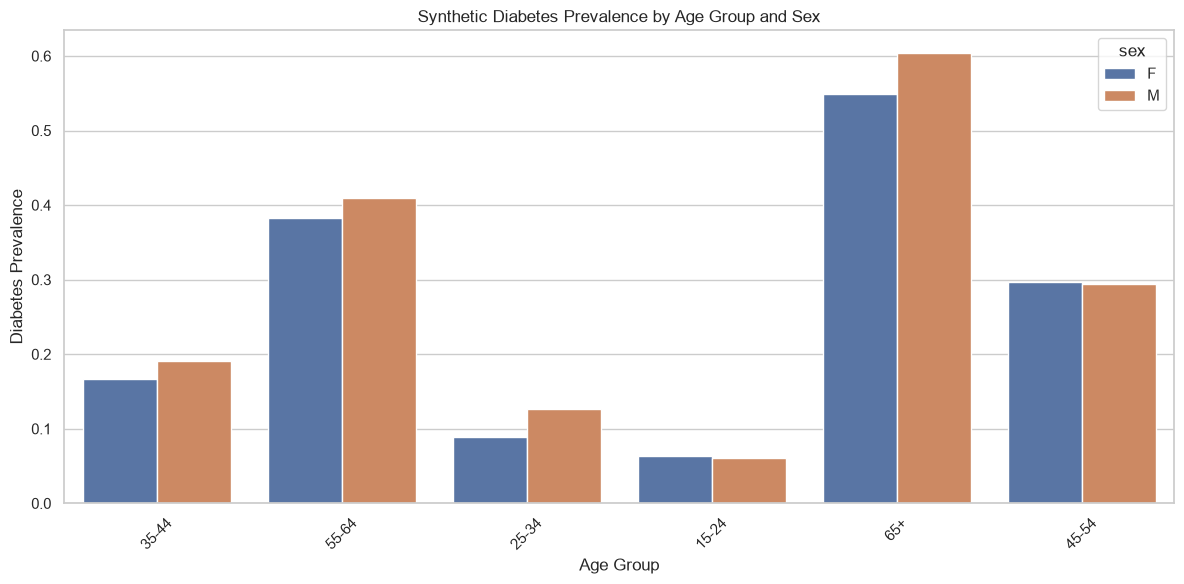

In [12]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Diabetes prevalence by age group
age_prevalence = (
    data.assign(
        is_diabetic=data["diabetes_status"].eq("diabetes")
    )
    .groupby("age_group", observed=False)["is_diabetic"]
    .agg(["sum", "count", "mean"])
    .reset_index()
)

age_prevalence["prevalence_pct"] = age_prevalence["mean"] * 100

display(age_prevalence)

# 2. Diabetes prevalence by sex
sex_prevalence = (
    data.assign(
        is_diabetic=data["diabetes_status"].eq("diabetes")
    )
    .groupby("sex", observed=False)["is_diabetic"]
    .agg(["sum", "count", "mean"])
    .reset_index()
)

sex_prevalence["prevalence_pct"] = sex_prevalence["mean"] * 100

display(sex_prevalence)

# 3. Visualize prevalence by age group and sex
plt.figure(figsize=(12, 6))

sns.barplot(
    data=data.assign(
        is_diabetic=data["diabetes_status"].eq("diabetes")
    ),
    x="age_group",
    y="is_diabetic",
    hue="sex",
    errorbar=None
)

plt.title("Synthetic Diabetes Prevalence by Age Group and Sex")
plt.xlabel("Age Group")
plt.ylabel("Diabetes Prevalence")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [13]:
prevalence_by_age_sex = (
    data.assign(
        diabetes=data["diabetes_status"].eq("diabetes")
    )
    .groupby(["age_group", "sex"], observed=False)
    .agg(
        total_records=("diabetes", "size"),
        diabetes_cases=("diabetes", "sum"),
        prevalence=("diabetes", "mean")
    )
    .reset_index()
)

prevalence_by_age_sex["prevalence_pct"] = (
    prevalence_by_age_sex["prevalence"] * 100
)

display(
    prevalence_by_age_sex[
        ["age_group", "sex", "total_records",
         "diabetes_cases", "prevalence_pct"]
    ].round(2)
)

,age_group,sex,total_records,diabetes_cases,prevalence_pct
0,15-24,F,1468,93,6.3400
1,15-24,M,1480,89,6.0100
2,25-34,F,1303,116,8.9000
3,25-34,M,1379,175,12.6900
4,35-44,F,974,163,16.7400
5,35-44,M,972,185,19.0300
6,45-54,F,604,179,29.6400
7,45-54,M,561,165,29.4100
8,55-64,F,366,140,38.2500
9,55-64,M,359,147,40.9500


## Chi-square Test by Age Group

In [14]:
import pandas as pd
import numpy as np
from scipy.stats import chi2_contingency

# Create a binary diabetes indicator
data["is_diabetic"] = (
    data["diabetes_status"].astype(str).str.strip().str.lower()
    == "diabetes"
)

results = []

for age_group, group in data.groupby("age_group", observed=True):

    # Contingency table: sex x diabetes status
    table = pd.crosstab(
        group["sex"],
        group["is_diabetic"]
    )

    # Skip groups without both sexes or both outcomes
    if table.shape != (2, 2):
        continue

    chi2, p_value, dof, expected = chi2_contingency(
        table, correction=False
    )

    n = table.to_numpy().sum()

    # Cramer's V for a 2x2 table
    cramers_v = np.sqrt(chi2 / n) if n > 0 else np.nan

    results.append({
        "age_group": age_group,
        "n": n,
        "chi2": chi2,
        "p_value": p_value,
        "cramers_v": cramers_v,
        "min_expected_count": expected.min()
    })

chi_square_results = pd.DataFrame(results)

display(chi_square_results.round(4))

,age_group,n,chi2,p_value,cramers_v,min_expected_count
0,15-24,2948,0.1316,0.7168,0.0067,90.6296
1,25-34,2682,9.9374,0.0016,0.0609,141.3770
2,35-44,1946,1.7492,0.1860,0.0300,173.8212
3,45-54,1165,0.0070,0.9333,0.0025,165.6515
4,55-64,725,0.5507,0.4580,0.0276,142.1145
5,65+,534,1.6281,0.2020,0.0552,106.2734


Correct for Multiple Testing 

In [15]:
from statsmodels.stats.multitest import multipletests

if not chi_square_results.empty:
    chi_square_results["p_adjusted"] = multipletests(
        chi_square_results["p_value"],
        method="fdr_bh"
    )[1]

    chi_square_results["significant"] = (
        chi_square_results["p_adjusted"] < 0.05
    )

display(chi_square_results.round(4))

,age_group,n,chi2,p_value,cramers_v,min_expected_count,p_adjusted,significant
0,15-24,2948,0.1316,0.7168,0.0067,90.6296,0.8601,False
1,25-34,2682,9.9374,0.0016,0.0609,141.3770,0.0097,True
2,35-44,1946,1.7492,0.1860,0.0300,173.8212,0.4039,False
3,45-54,1165,0.0070,0.9333,0.0025,165.6515,0.9333,False
4,55-64,725,0.5507,0.4580,0.0276,142.1145,0.6871,False
5,65+,534,1.6281,0.2020,0.0552,106.2734,0.4039,False


Age Group 25–34
The adjusted p-value (p_adjusted = 0.0097) is below 0.05, indicating statistically significant evidence of a difference in diabetes prevalence between males and females within this age group in the synthetic dataset.
However, the effect size is very small (Cramér’s V = 0.0609).

## Identifying the Direction of the Difference

In [16]:
target_group = "25-34"

subset = data[
    data["age_group"].astype(str).str.strip() == target_group
].copy()

gender_comparison = (
    subset.assign(
        diabetes=subset["diabetes_status"].astype(str).str.strip().str.lower()
        .eq("diabetes")
    )
    .groupby("sex", observed=True)
    .agg(
        total=("diabetes", "size"),
        diabetes_cases=("diabetes", "sum"),
        prevalence=("diabetes", "mean")
    )
    .reset_index()
)

gender_comparison["prevalence_pct"] = (
    gender_comparison["prevalence"] * 100
)

display(gender_comparison.round(3))

,sex,total,diabetes_cases,prevalence,prevalence_pct
0,F,1303,116,0.0890,8.9030
1,M,1379,175,0.1270,12.6900


## Identifying the Direction of the Difference

We have now identified the direction of the difference in the 25–34 age group: diabetes prevalence is higher among males in the synthetic dataset.

1. Interpretation of the Results

Indicator	Females (F)	Males (M)
Number of individuals	1,303	1,379
Diabetes cases	116	175
Diabetes prevalence	8.90%	12.69%

* The difference in prevalence is 3.79 percentage points, with higher prevalence among males.
* The previous chi-square test indicated a statistically significant difference after adjusting for multiple comparisons.
* The effect size is very small.

For reference, data from the 2013 Saudi Health Interview Survey showed that the prevalence of diagnosed diabetes in the 25–34 age group was 7.82% among males and 5.70% among females. The direction of the difference in the synthetic dataset is consistent with this finding. However, this does not mean that the synthetic dataset is statistically representative of the Saudi population.

## odds Ratio 

In [17]:
from statsmodels.stats.contingency_tables import Table2x2

subset = data[
    data["age_group"].astype(str).str.strip() == "25-34"
].copy()

subset["is_diabetic"] = (
    subset["diabetes_status"].astype(str).str.strip().str.lower()
    == "diabetes"
)

# Rows: Male, Female
# Columns: Diabetes, No diabetes
table = pd.crosstab(
    subset["sex"],
    subset["is_diabetic"]
).reindex(index=["M", "F"], columns=[True, False])

print("Contingency table:")
display(table)

result = Table2x2(table.to_numpy())

print(f"Odds Ratio (Male vs Female): {result.oddsratio:.3f}")
print(f"95% CI: {result.oddsratio_confint()[0]:.3f} to "
      f"{result.oddsratio_confint()[1]:.3f}")

Contingency table:


is_diabetic,True,False
sex,,
M,175,1204
F,116,1187


Odds Ratio (Male vs Female): 1.487
95% CI: 1.161 to 1.906


The result indicates that the odds of having diabetes among males are approximately 48.7% higher than among females in the synthetic dataset.

# Calibration Against Published Saudi Studies

Define Reference Values 

In [18]:
import pandas as pd
import numpy as np

# Reference values from published Saudi studies.
# Add a value only after verifying its source and definition.

reference_data = pd.DataFrame([
    {
        "study": "Saudi Health Interview Survey 2013",
        "year": 2013,
        "age_group": "25-34",
        "sex": "F",
        "reference_prevalence_pct": 5.9,
        "definition": "Published diabetes prevalence estimate",
        "source_verified": True
    },
    {
        "study": "Saudi Health Interview Survey 2013",
        "year": 2013,
        "age_group": "25-34",
        "sex": "M",
        "reference_prevalence_pct": 9.5,
        "definition": "Published diabetes prevalence estimate",
        "source_verified": True
    }
])

display(reference_data)

,study,year,age_group,sex,reference_prevalence_pct,definition,source_verified
0,Saudi Health Interview Survey 2013,2013,25-34,F,5.9000,Published diabetes prevalence estimate,True
1,Saudi Health Interview Survey 2013,2013,25-34,M,9.5000,Published diabetes prevalence estimate,True


## Compare Synthetic and Reference Prevalence

Calculate synthetic prevalence by age group and sex

In [19]:
synthetic_prevalence = (
    data.assign(
        is_diabetic=(
            data["diabetes_status"].astype(str).str.strip().str.lower()
            == "diabetes"
        )
    )
    .groupby(["age_group", "sex"], observed=True)
    .agg(
        total=("is_diabetic", "size"),
        cases=("is_diabetic", "sum"),
        synthetic_prevalence_pct=("is_diabetic", "mean")
    )
    .reset_index()
)

synthetic_prevalence["synthetic_prevalence_pct"] *= 100

# Compare only matching age groups and sexes
calibration_comparison = synthetic_prevalence.merge(
    reference_data[
        ["age_group", "sex", "reference_prevalence_pct"]
    ],
    on=["age_group", "sex"],
    how="inner"
)

calibration_comparison["difference_pp"] = (
    calibration_comparison["synthetic_prevalence_pct"]
    - calibration_comparison["reference_prevalence_pct"]
)

calibration_comparison["absolute_difference_pp"] = (
    calibration_comparison["difference_pp"].abs()
)

display(calibration_comparison.round(2))

,age_group,sex,total,cases,synthetic_prevalence_pct,reference_prevalence_pct,difference_pp,absolute_difference_pp
0,25-34,F,1303,116,8.9000,5.9000,3.0000,3.0000
1,25-34,M,1379,175,12.6900,9.5000,3.1900,3.1900


In [20]:
reference_data = pd.DataFrame([
    {"age_group": "15-24", "sex": "M", "reference_pct": 4.0},
    {"age_group": "15-24", "sex": "F", "reference_pct": 5.4},
    {"age_group": "25-34", "sex": "M", "reference_pct": 9.5},
    {"age_group": "25-34", "sex": "F", "reference_pct": 5.9},
    {"age_group": "35-44", "sex": "M", "reference_pct": 14.5},
    {"age_group": "35-44", "sex": "F", "reference_pct": 10.5},
    {"age_group": "45-54", "sex": "M", "reference_pct": 30.9},
    {"age_group": "45-54", "sex": "F", "reference_pct": 22.5},
    {"age_group": "55-64", "sex": "M", "reference_pct": 53.0},
    {"age_group": "55-64", "sex": "F", "reference_pct": 41.6},
    {"age_group": "65+", "sex": "M", "reference_pct": 51.8},
    {"age_group": "65+", "sex": "F", "reference_pct": 48.2},
])

In [21]:
comparison = synthetic_prevalence.merge(
    reference_data,
    on=["age_group", "sex"],
    how="inner"
)

comparison["difference_pp"] = (
    comparison["synthetic_prevalence_pct"]
    - comparison["reference_pct"]
)

comparison["absolute_difference_pp"] = (
    comparison["difference_pp"].abs()
)

display(
    comparison[
        [
            "age_group", "sex", "total", "cases",
            "synthetic_prevalence_pct", "reference_pct",
            "difference_pp", "absolute_difference_pp"
        ]
    ].round(2)
)

,age_group,sex,total,cases,synthetic_prevalence_pct,reference_pct,difference_pp,absolute_difference_pp
0,15-24,F,1468,93,6.3400,5.4000,0.9400,0.9400
1,15-24,M,1480,89,6.0100,4.0000,2.0100,2.0100
2,25-34,F,1303,116,8.9000,5.9000,3.0000,3.0000
3,25-34,M,1379,175,12.6900,9.5000,3.1900,3.1900
4,35-44,F,974,163,16.7400,10.5000,6.2400,6.2400
5,35-44,M,972,185,19.0300,14.5000,4.5300,4.5300
6,45-54,F,604,179,29.6400,22.5000,7.1400,7.1400
7,45-54,M,561,165,29.4100,30.9000,-1.4900,1.4900
8,55-64,F,366,140,38.2500,41.6000,-3.3500,3.3500
9,55-64,M,359,147,40.9500,53.0000,-12.0500,12.0500


In [22]:
mae = comparison["absolute_difference_pp"].mean()

print(f"Mean Absolute Error (MAE): {mae:.2f} percentage points")

Mean Absolute Error (MAE): 4.94 percentage points


In [23]:
comparison_sorted = comparison.sort_values(
    "absolute_difference_pp",
    ascending=False
)

display(
    comparison_sorted[
        [
            "age_group",
            "sex",
            "synthetic_prevalence_pct",
            "reference_pct",
            "difference_pp",
            "absolute_difference_pp"
        ]
    ].round(2)
)

,age_group,sex,synthetic_prevalence_pct,reference_pct,difference_pp,absolute_difference_pp
9,55-64,M,40.9500,53.0000,-12.0500,12.0500
11,65+,M,60.4000,51.8000,8.6000,8.6000
6,45-54,F,29.6400,22.5000,7.1400,7.1400
10,65+,F,54.9300,48.2000,6.7300,6.7300
4,35-44,F,16.7400,10.5000,6.2400,6.2400
5,35-44,M,19.0300,14.5000,4.5300,4.5300
8,55-64,F,38.2500,41.6000,-3.3500,3.3500
3,25-34,M,12.6900,9.5000,3.1900,3.1900
2,25-34,F,8.9000,5.9000,3.0000,3.0000
1,15-24,M,6.0100,4.0000,2.0100,2.0100


## Largest Prevalence Differences

* Males aged 55–64: Synthetic 40.95% vs. Reference 53.00% (−12.05 percentage points).
* Males aged 65+: Synthetic 60.40% vs. Reference 51.80% (+8.60 percentage points).
* Females aged 45–54: Synthetic 29.64% vs. Reference 22.50% (+7.14 percentage points).

Statistical Interpretation

The largest discrepancy occurs among males aged 55–64, where the synthetic prevalence is 12.05 percentage points below the reference value. In contrast, males aged 65+ and females aged 45–54 show higher synthetic prevalence than the reference values.

These differences indicate imperfect calibration across age and sex subgroups. The synthetic data may reproduce the overall prevalence while misrepresenting specific demographic groups.

Recommended next step: Adjust subgroup-specific prevalence parameters and reassess calibration. These differences are descriptive; statistical significance cannot be established without sample sizes, uncertainty estimates, and an appropriate statistical test. Since the data are synthetic, the findings reflect the simulation rather than actual Saudi patients.

In [24]:
check = (
    data.assign(
        diabetes=data["diabetes_status"].astype(str).str.strip().str.lower()
        .eq("diabetes")
    )
    .groupby(["age_group", "sex"], observed=True)
    .agg(
        total=("diabetes", "size"),
        cases=("diabetes", "sum"),
        prevalence_pct=("diabetes", "mean")
    )
    .reset_index()
)

check["prevalence_pct"] *= 100
display(check.round(2))

,age_group,sex,total,cases,prevalence_pct
0,15-24,F,1468,93,6.3400
1,15-24,M,1480,89,6.0100
2,25-34,F,1303,116,8.9000
3,25-34,M,1379,175,12.6900
4,35-44,F,974,163,16.7400
5,35-44,M,972,185,19.0300
6,45-54,F,604,179,29.6400
7,45-54,M,561,165,29.4100
8,55-64,F,366,140,38.2500
9,55-64,M,359,147,40.9500


## Create Reference Dataset

In [25]:
import pandas as pd
import numpy as np

# Reference prevalence percentages from Saudi Health Interview Survey (2013)
reference_data = pd.DataFrame([
    {"age_group": "15-24", "sex": "M", "reference_pct": 4.0},
    {"age_group": "15-24", "sex": "F", "reference_pct": 5.4},
    {"age_group": "25-34", "sex": "M", "reference_pct": 9.5},
    {"age_group": "25-34", "sex": "F", "reference_pct": 5.9},
    {"age_group": "35-44", "sex": "M", "reference_pct": 14.5},
    {"age_group": "35-44", "sex": "F", "reference_pct": 10.5},
    {"age_group": "45-54", "sex": "M", "reference_pct": 30.9},
    {"age_group": "45-54", "sex": "F", "reference_pct": 22.5},
    {"age_group": "55-64", "sex": "M", "reference_pct": 53.0},
    {"age_group": "55-64", "sex": "F", "reference_pct": 41.6},
    {"age_group": "65+",   "sex": "M", "reference_pct": 51.8},
    {"age_group": "65+",   "sex": "F", "reference_pct": 48.2},
])

reference_data

,age_group,sex,reference_pct
0,15-24,M,4.0000
1,15-24,F,5.4000
2,25-34,M,9.5000
3,25-34,F,5.9000
4,35-44,M,14.5000
5,35-44,F,10.5000
6,45-54,M,30.9000
7,45-54,F,22.5000
8,55-64,M,53.0000
9,55-64,F,41.6000


Calculate Synthetic Prevalence

In [26]:
data["is_diabetic"] = (
    data["diabetes_status"]
    .astype(str)
    .str.strip()
    .str.lower()
    .eq("diabetes")
)

synthetic_data = (
    data.groupby(["age_group", "sex"], observed=True)
    .agg(
        total=("is_diabetic", "size"),
        diabetes_cases=("is_diabetic", "sum")
    )
    .reset_index()
)

synthetic_data["synthetic_pct"] = (
    synthetic_data["diabetes_cases"]
    / synthetic_data["total"] * 100
)

synthetic_data

,age_group,sex,total,diabetes_cases,synthetic_pct
0,15-24,F,1468,93,6.3351
1,15-24,M,1480,89,6.0135
2,25-34,F,1303,116,8.9025
3,25-34,M,1379,175,12.6904
4,35-44,F,974,163,16.7351
5,35-44,M,972,185,19.0329
6,45-54,F,604,179,29.6358
7,45-54,M,561,165,29.4118
8,55-64,F,366,140,38.2514
9,55-64,M,359,147,40.9471


Compare and Calculate Errors

In [27]:
comparison = synthetic_data.merge(
    reference_data,
    on=["age_group", "sex"],
    how="inner",
    validate="one_to_one"
)

comparison["error_pp"] = (
    comparison["synthetic_pct"] - comparison["reference_pct"]
)

comparison["absolute_error_pp"] = comparison["error_pp"].abs()

comparison["result"] = np.where(
    comparison["error_pp"] > 0,
    "Synthetic prevalence is higher",
    np.where(
        comparison["error_pp"] < 0,
        "Synthetic prevalence is lower",
        "Exact match"
    )
)

comparison = comparison.sort_values(
    ["age_group", "sex"]
).reset_index(drop=True)

display(comparison.round(2))

mae = comparison["absolute_error_pp"].mean()
rmse = np.sqrt((comparison["error_pp"] ** 2).mean())

print(f"Mean Absolute Error (MAE): {mae:.2f} percentage points")
print(f"Root Mean Squared Error (RMSE): {rmse:.2f} percentage points")

,age_group,sex,total,diabetes_cases,synthetic_pct,reference_pct,error_pp,absolute_error_pp,result
0,15-24,F,1468,93,6.3400,5.4000,0.9400,0.9400,Synthetic prevalence is higher
1,15-24,M,1480,89,6.0100,4.0000,2.0100,2.0100,Synthetic prevalence is higher
2,25-34,F,1303,116,8.9000,5.9000,3.0000,3.0000,Synthetic prevalence is higher
3,25-34,M,1379,175,12.6900,9.5000,3.1900,3.1900,Synthetic prevalence is higher
4,35-44,F,974,163,16.7400,10.5000,6.2400,6.2400,Synthetic prevalence is higher
5,35-44,M,972,185,19.0300,14.5000,4.5300,4.5300,Synthetic prevalence is higher
6,45-54,F,604,179,29.6400,22.5000,7.1400,7.1400,Synthetic prevalence is higher
7,45-54,M,561,165,29.4100,30.9000,-1.4900,1.4900,Synthetic prevalence is lower
8,55-64,F,366,140,38.2500,41.6000,-3.3500,3.3500,Synthetic prevalence is lower
9,55-64,M,359,147,40.9500,53.0000,-12.0500,12.0500,Synthetic prevalence is lower


Mean Absolute Error (MAE): 4.94 percentage points
Root Mean Squared Error (RMSE): 5.86 percentage points


Visualize Calibration

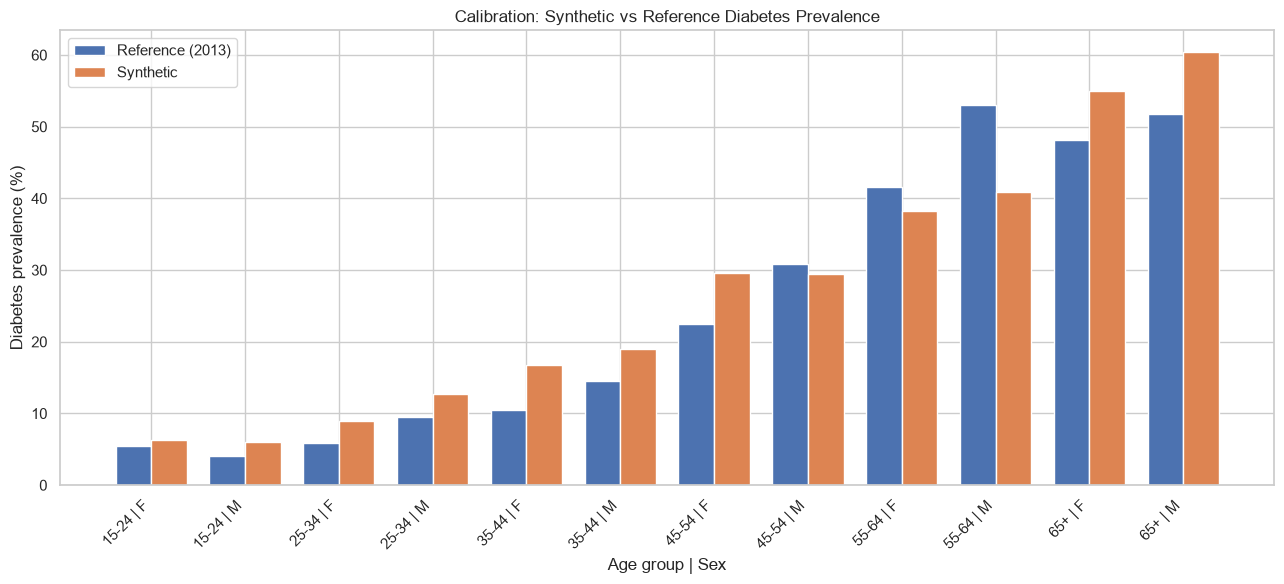

In [28]:
import matplotlib.pyplot as plt
import seaborn as sns

plot_data = comparison.copy()
plot_data["group_label"] = (
    plot_data["age_group"] + " | " + plot_data["sex"]
)

plot_data = plot_data.sort_values(
    ["age_group", "sex"]
)

x = np.arange(len(plot_data))
width = 0.38

plt.figure(figsize=(13, 6))

plt.bar(
    x - width / 2,
    plot_data["reference_pct"],
    width,
    label="Reference (2013)"
)

plt.bar(
    x + width / 2,
    plot_data["synthetic_pct"],
    width,
    label="Synthetic"
)

plt.xticks(x, plot_data["group_label"], rotation=45, ha="right")
plt.ylabel("Diabetes prevalence (%)")
plt.xlabel("Age group | Sex")
plt.title("Calibration: Synthetic vs Reference Diabetes Prevalence")
plt.legend()
plt.tight_layout()
plt.show()

The synthetic dataset tends to overestimate diabetes prevalence across most demographic groups, with the largest underestimation observed among males aged 55–64.

* Largest negative deviation: Males aged 55–64 (40.95% vs. 53.00%; −12.05 percentage points).
* Largest positive deviation in males: Age 65+ (60.40% vs. 51.80%; +8.60 percentage points).
* Largest positive deviation in females: Ages 45–54 (29.64% vs. 22.50%; +7.14 percentage points).

Calibration Metrics

* MAE: 4.94 percentage points.
* RMSE: 5.86 percentage points.
* Direction of deviation: 9 of 12 demographic groups show overestimation, while 3 show underestimation.

Statistical Interpretation

The RMSE exceeding the MAE indicates that larger deviations contribute disproportionately to the overall calibration error. The predominantly positive deviations suggest a systematic tendency to overestimate prevalence. Further subgroup-specific calibration is recommended to improve alignment with reference estimates.

Note: These metrics measure agreement with the selected reference values and do not establish statistical significance or validate the synthetic data against actual patient-level outcomes.

## Calibration Deviation Plot

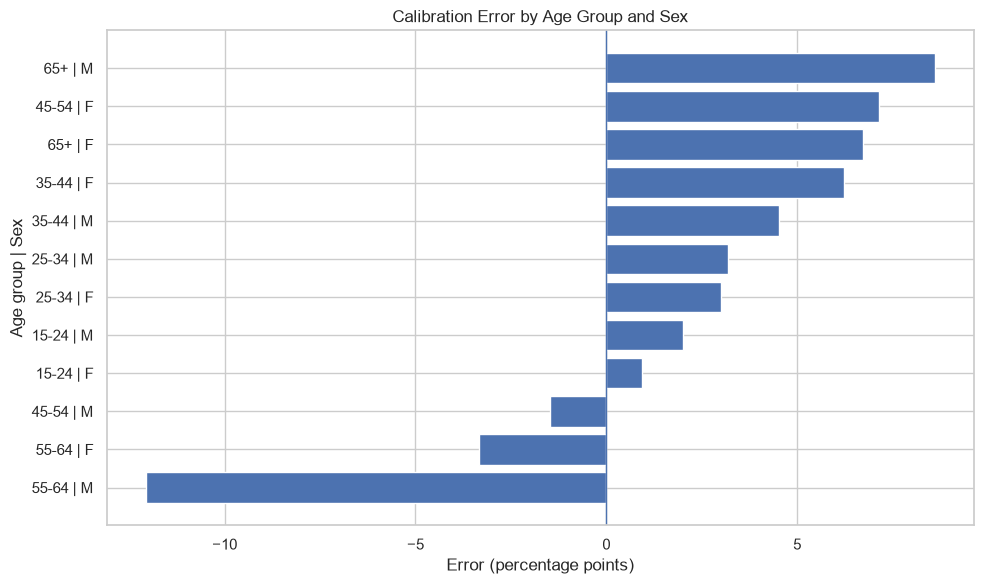

Mean signed error: 2.12 percentage points


In [29]:
import matplotlib.pyplot as plt

plot_data = comparison.copy()
plot_data["group_label"] = (
    plot_data["age_group"] + " | " + plot_data["sex"]
)
plot_data = plot_data.sort_values("error_pp")

plt.figure(figsize=(10, 6))
plt.barh(plot_data["group_label"], plot_data["error_pp"])
plt.axvline(0, linewidth=1)
plt.xlabel("Error (percentage points)")
plt.ylabel("Age group | Sex")
plt.title("Calibration Error by Age Group and Sex")
plt.tight_layout()
plt.show()

print("Mean signed error:",
      round(comparison["error_pp"].mean(), 2),
      "percentage points")

In [30]:
calibration_check = (
    data.assign(
        is_diabetic=data["diabetes_status"]
        .astype(str)
        .str.strip()
        .str.lower()
        .eq("diabetes")
    )
    .groupby(["age_group", "sex"], observed=True)
    .agg(
        sample_size=("is_diabetic", "size"),
        diabetes_cases=("is_diabetic", "sum"),
        prevalence_pct=("is_diabetic", lambda x: x.mean() * 100)
    )
    .reset_index()
)

display(calibration_check.round(2))

,age_group,sex,sample_size,diabetes_cases,prevalence_pct
0,15-24,F,1468,93,6.3400
1,15-24,M,1480,89,6.0100
2,25-34,F,1303,116,8.9000
3,25-34,M,1379,175,12.6900
4,35-44,F,974,163,16.7400
5,35-44,M,972,185,19.0300
6,45-54,F,604,179,29.6400
7,45-54,M,561,165,29.4100
8,55-64,F,366,140,38.2500
9,55-64,M,359,147,40.9500


# Data Quality Assesment

In [31]:
import pandas as pd
import numpy as np

# 1. Check missing values
missing_values = data.isna().sum()

# 2. Check duplicate IDs
duplicate_ids = data["id"].duplicated().sum()

# 3. Summarize diabetes status
status_summary = (
    data["diabetes_status"]
    .value_counts(dropna=False)
    .rename_axis("diabetes_status")
    .reset_index(name="count")
)

status_summary["percentage"] = (
    status_summary["count"] / len(data) * 100
).round(2)

# 4. Summarize HbA1c by diabetes status
hba1c_summary = (
    data.groupby("diabetes_status")["hba1c"]
    .agg(["count", "mean", "median", "min", "max"])
    .round(2)
)

print("Dataset shape:", data.shape)
print("\nMissing values:")
print(missing_values[missing_values > 0])

print("\nDuplicate IDs:", duplicate_ids)

print("\nDiabetes status distribution:")
display(status_summary)

print("\nHbA1c summary by diabetes status:")
display(hba1c_summary)

Dataset shape: (10000, 20)

Missing values:
Series([], dtype: int64)

Duplicate IDs: 0

Diabetes status distribution:


,diabetes_status,count,percentage
0,normal,7073,70.7300
1,diabetes,1759,17.5900
2,prediabetes,1168,11.6800



HbA1c summary by diabetes status:


,count,mean,median,min,max
diabetes_status,,,,,
diabetes,1759,7.8800,7.7700,6.0000,11.6900
normal,7073,5.2400,5.2600,4.5000,5.6900
prediabetes,1168,6.0200,6.0100,5.7000,6.4700


HbA1c Distribution by Diabetes Status

Mean HbA1c levels follow the expected increasing pattern across health categories:

* Normal: 5.24%
* Prediabetes: 6.02%
* Diabetes: 7.88%

This pattern suggests that the generated HbA1c values are broadly consistent with the assigned diabetes status.

Methodological consideration: The standard HbA1c thresholds are 5.7–6.4% for prediabetes and ≥6.5% for diabetes. Therefore, individual values below 6.5% within the diabetes group warrant further examination of the status-assignment rules, particularly if diabetes status was intended to be determined solely by HbA1c.

These results describe synthetic data and do not validate clinical diagnostic accuracy.

## Indicator Consistency Assessment

In [32]:
data["hba1c_category"] = pd.cut(
    data["hba1c"],
    bins=[-np.inf, 5.7, 6.5, np.inf],
    labels=["normal", "prediabetes", "diabetes"],
    right=False
)

data["glucose_category"] = pd.cut(
    data["fasting_glucose_mmol"],
    bins=[-np.inf, 5.6, 7.0, np.inf],
    labels=["normal", "prediabetes", "diabetes"],
    right=False
)

print("Status vs HbA1c category")
display(pd.crosstab(
    data["diabetes_status"],
    data["hba1c_category"],
    margins=True
))

print("Status vs fasting glucose category")
display(pd.crosstab(
    data["diabetes_status"],
    data["glucose_category"],
    margins=True
))

print("HbA1c outside the expected range for each status:")
display(
    data.groupby("diabetes_status")["hba1c"]
    .agg(["min", "max"])
    .round(2)
)

Status vs HbA1c category


hba1c_category,normal,prediabetes,diabetes,All
diabetes_status,,,,
diabetes,0,138,1621,1759
normal,7073,0,0,7073
prediabetes,0,1168,0,1168
All,7073,1306,1621,10000


Status vs fasting glucose category


glucose_category,normal,prediabetes,diabetes,All
diabetes_status,,,,
diabetes,4,132,1623,1759
normal,4877,2131,65,7073
prediabetes,110,807,251,1168
All,4991,3070,1939,10000


HbA1c outside the expected range for each status:


,min,max
diabetes_status,,
diabetes,6.0000,11.6900
normal,4.5000,5.6900
prediabetes,5.7000,6.4700


In [33]:
agreement = (
    data["hba1c_category"].astype(str)
    == data["glucose_category"].astype(str)
)

print("HbA1c–glucose agreement:")
print(f"{agreement.mean() * 100:.2f}%")

print("\nHbA1c–glucose disagreement:")
print(f"{(~agreement).mean() * 100:.2f}%")

# Compare both biomarkers with the recorded status
hba1c_match = (
    data["diabetes_status"].astype(str)
    == data["hba1c_category"].astype(str)
)

glucose_match = (
    data["diabetes_status"].astype(str)
    == data["glucose_category"].astype(str)
)

print("\nStatus agreement with HbA1c:")
print(f"{hba1c_match.mean() * 100:.2f}%")

print("\nStatus agreement with fasting glucose:")
print(f"{glucose_match.mean() * 100:.2f}%")

HbA1c–glucose agreement:
73.15%

HbA1c–glucose disagreement:
26.85%

Status agreement with HbA1c:
98.62%

Status agreement with fasting glucose:
73.07%


Indicator Consistency Assessment

Key Results

* Status–HbA1c agreement: 98.62%
* Status–fasting glucose agreement: 73.07%
* HbA1c–glucose agreement: 73.15%
* Indicator disagreement: 26.85%

Statistical Interpretation

HbA1c shows very high agreement with recorded diabetes status (98.62%), while fasting glucose agreement is lower (73.07%). The 26.85% disagreement between indicators warrants further investigation.

However, high HbA1c agreement does not independently establish data validity, particularly if HbA1c values were generated based on the assigned diabetes status. These findings reflect internal consistency within the synthetic dataset, not clinical validity.

## Correlation Analysis

In [34]:
from scipy.stats import spearmanr, pearsonr

# Correlation between synthetic biomarkers
pearson_r, pearson_p = pearsonr(
    data["hba1c"],
    data["fasting_glucose_mmol"]
)

spearman_r, spearman_p = spearmanr(
    data["hba1c"],
    data["fasting_glucose_mmol"]
)

print("Pearson correlation:", round(pearson_r, 3))
print("Pearson p-value:", pearson_p)

print("\nSpearman correlation:", round(spearman_r, 3))
print("Spearman p-value:", spearman_p)

Pearson correlation: 0.948
Pearson p-value: 0.0

Spearman correlation: 0.809
Spearman p-value: 0.0


Correlation Analysis

Results

* Pearson correlation: (r = 0.948) — very strong positive linear correlation.
* Spearman correlation: (\rho = 0.809) — strong positive rank correlation.
* P-values: (p < 0.001) for both correlations.

Statistical Interpretation

Both coefficients indicate a strong positive association between HbA1c and fasting blood glucose. The lower Spearman coefficient suggests that the relationship between ranked values is weaker than the linear association captured by Pearson.

Despite this strong correlation, the two indicators agree in classification in only 73.15% of records. This is not necessarily contradictory, as correlation measures association between values rather than agreement between diagnostic categories.

Overall Findings

* No missing values or duplicate identifiers were detected.
* HbA1c and fasting glucose exhibit a strong positive correlation.
* Classification agreement remains limited to 73.15%, warranting further consistency checks.

These findings describe the synthetic dataset and do not establish clinical validity.

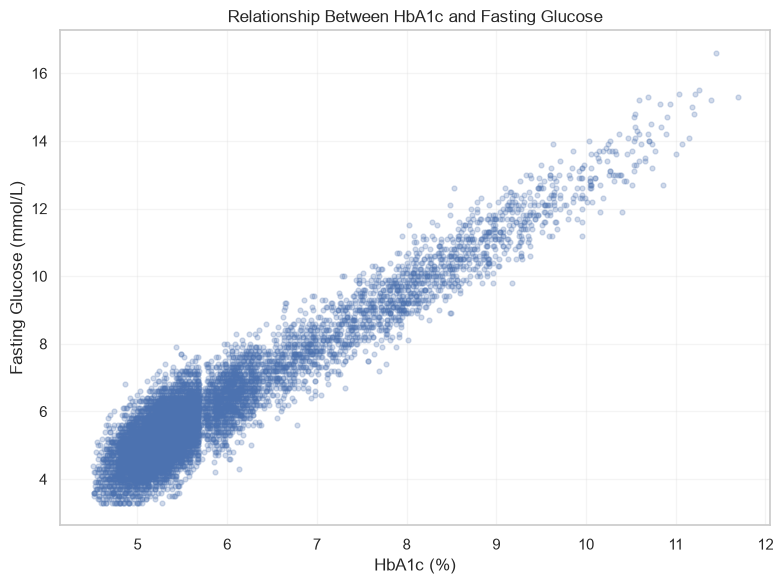

In [35]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))

plt.scatter(
    data["hba1c"],
    data["fasting_glucose_mmol"],
    alpha=0.25,
    s=12
)

plt.xlabel("HbA1c (%)")
plt.ylabel("Fasting Glucose (mmol/L)")
plt.title("Relationship Between HbA1c and Fasting Glucose")
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

# Hypothesis Test:

 Famliy History VS diabetes

In [36]:
import pandas as pd
from scipy.stats import chi2_contingency

# Create a binary diabetes outcome
data["is_diabetic"] = (
    data["diabetes_status"]
    .astype(str)
    .str.strip()
    .str.lower()
    .eq("diabetes")
)

# Check the variable values first
print("Family history values:")
print(data["family_history"].value_counts(dropna=False))

# Build contingency table
table = pd.crosstab(
    data["family_history"],
    data["is_diabetic"]
)

display(table)

# Chi-square test
chi2, p_value, dof, expected = chi2_contingency(table)

# Cramer's V
n = table.to_numpy().sum()
cramers_v = (chi2 / n) ** 0.5

print(f"Chi-square statistic: {chi2:.3f}")
print(f"Degrees of freedom: {dof}")
print(f"P-value: {p_value:.6g}")
print(f"Cramer's V: {cramers_v:.3f}")
print(f"Minimum expected count: {expected.min():.2f}")

if p_value < 0.05:
    print("Decision: Reject H0 at alpha = 0.05")
else:
    print("Decision: Fail to reject H0 at alpha = 0.05")

Family history values:
family_history
0    6448
1    3552
Name: count, dtype: int64


is_diabetic,False,True
family_history,,
0,5446,1002
1,2795,757


Chi-square statistic: 52.246
Degrees of freedom: 1
P-value: 4.8978e-13
Cramer's V: 0.072
Minimum expected count: 624.80
Decision: Reject H0 at alpha = 0.05


## Hypothesis Test: Family History vs. Diabetes Status

Statistical Results

Metric	Result
Chi-square statistic	52.246
Degrees of freedom	1
P-value	4.90 × 10⁻¹³
Cramér’s V	0.072
Decision	Reject H₀

Interpretation

A statistically significant association was observed between family history and diabetes status ((p < 0.001)). However, the effect size was small (Cramér’s V = 0.072).

Family history	Diabetes prevalence
Absent	15.54%
Present	21.31%

Diabetes prevalence was 5.77 percentage points higher among individuals with a family history of diabetes.

These findings reflect associations within the synthetic dataset and do not establish causality or confirm the same relationship in the Saudi population.

Next Test: BMI Category vs. Diabetes Status, using a chi-square test of independence and Cramér’s V to assess association and effect size.

## BMI Category VS Diabetes Status

In [37]:
print(data["bmi_category"].value_counts(dropna=False))

bmi_category
normal         3372
overweight     2996
obese          2568
underweight     713
morbid          351
Name: count, dtype: int64


BMI Category distribution

In [38]:
bmi_counts = data["bmi_category"].value_counts()

display(
    bmi_counts.rename("count").to_frame()
    .assign(percentage=lambda x: (x["count"] / len(data) * 100).round(2))
)

,count,percentage
bmi_category,,
normal,3372,33.7200
overweight,2996,29.9600
obese,2568,25.6800
underweight,713,7.1300
morbid,351,3.5100


 BMI Category vs Diabetes Status: Chi-square Test

In [39]:
import pandas as pd
import numpy as np
from scipy.stats import chi2_contingency

# Create contingency table
table = pd.crosstab(
    data["bmi_category"],
    data["diabetes_status"]
)

display(table)

# Chi-square test
chi2, p_value, dof, expected = chi2_contingency(table)

# Cramér's V effect size
n = table.to_numpy().sum()
min_dimension = min(table.shape[0] - 1, table.shape[1] - 1)
cramers_v = np.sqrt(chi2 / (n * min_dimension))

print("Chi-square Test Results")
print("-" * 35)
print(f"Chi-square statistic: {chi2:.3f}")
print(f"Degrees of freedom: {dof}")
print(f"P-value: {p_value:.6e}")
print(f"Cramér's V: {cramers_v:.3f}")
print(f"Minimum expected count: {expected.min():.2f}")

alpha = 0.05

if p_value < alpha:
    print("\nDecision: Reject H0")
    print("There is a statistically significant association between BMI category and diabetes status.")
else:
    print("\nDecision: Fail to reject H0")
    print("There is insufficient evidence of an association between BMI category and diabetes status.")

diabetes_status,diabetes,normal,prediabetes
bmi_category,,,
morbid,114,185,52
normal,245,2853,274
obese,754,1473,341
overweight,614,1935,447
underweight,32,627,54


Chi-square Test Results
-----------------------------------
Chi-square statistic: 835.761
Degrees of freedom: 8
P-value: 4.026277e-175
Cramér's V: 0.204
Minimum expected count: 41.00

Decision: Reject H0
There is a statistically significant association between BMI category and diabetes status.


Diabetes Prevalence by BMI Category

In [40]:
prevalence = (
    data.assign(
        is_diabetic=data["diabetes_status"].astype(str).str.strip().str.lower().eq("diabetes")
    )
    .groupby("bmi_category", observed=False)
    .agg(
        total=("is_diabetic", "size"),
        diabetes_cases=("is_diabetic", "sum"),
        diabetes_prevalence=("is_diabetic", "mean")
    )
)

prevalence["diabetes_prevalence_pct"] = (
    prevalence["diabetes_prevalence"] * 100
).round(2)

display(prevalence.drop(columns="diabetes_prevalence"))

,total,diabetes_cases,diabetes_prevalence_pct
bmi_category,,,
morbid,351,114,32.4800
normal,3372,245,7.2700
obese,2568,754,29.3600
overweight,2996,614,20.4900
underweight,713,32,4.4900


In [41]:
# Check Expected Frequencies

expected_df = pd.DataFrame(
    expected,
    index=table.index,
    columns=table.columns
)

display(expected_df.round(2))

print("All expected counts >= 5:", (expected >= 5).all())

diabetes_status,diabetes,normal,prediabetes
bmi_category,,,
morbid,61.7400,248.2600,41.0000
normal,593.1300,2385.0200,393.8500
obese,451.7100,1816.3500,299.9400
overweight,527.0000,2119.0700,349.9300
underweight,125.4200,504.3000,83.2800


All expected counts >= 5: True


Hypothesis Test: BMI Category vs. Diabetes Status

Statistical Results

Metric	Result
Chi-square statistic	835.761
Degrees of freedom	8
P-value	p < 0.001
Cramér’s V	0.204
Minimum expected count	41.00
Decision	Reject H₀

Interpretation

A statistically significant association was found between BMI category and diabetes status ((p < 0.001)). Cramér’s V = 0.204 indicates a moderate association under commonly used guidelines. The minimum expected count (41.00) exceeds 5, satisfying the expected-frequency assumption for the chi-square test.

Diabetes Prevalence by BMI Category

BMI category	Diabetes cases / Total	Prevalence
Underweight	32 / 713	4.49%
Normal	245 / 3,372	7.27%
Overweight	614 / 2,996	20.49%
Obese	754 / 2,568	29.36%
Morbidly obese	114 / 351	32.48%

Key Finding

Diabetes prevalence increases overall with BMI category, rising from 7.27% among individuals with normal weight to 32.48% among those with morbid obesity.

These findings describe associations in the synthetic dataset and do not establish causality or confirm equivalent prevalence patterns in the Saudi population.

Adjusted Standardized Residuals

In [42]:
row_totals = table.sum(axis=1).to_numpy()[:, None]
col_totals = table.sum(axis=0).to_numpy()[None, :]
n = table.to_numpy().sum()

expected_values = row_totals * col_totals / n

adjusted_residuals = (
    table.to_numpy() - expected_values
) / np.sqrt(
    expected_values
    * (1 - row_totals / n)
    * (1 - col_totals / n)
)

residuals_df = pd.DataFrame(
    adjusted_residuals,
    index=table.index,
    columns=table.columns
)

display(residuals_df.round(2))

diabetes_status,diabetes,normal,prediabetes
bmi_category,,,
morbid,7.4600,-7.5600,1.8600
normal,-19.3400,21.7600,-7.8900
obese,18.1700,-17.2700,2.9300
overweight,4.9900,-8.8300,6.6000
underweight,-9.5300,10.4800,-3.5400


Post-hoc Analysis with Benjamini-Hochberg Correction

In [43]:
from scipy.stats import norm
from statsmodels.stats.multitest import multipletests

posthoc = residuals_df.stack().rename("adjusted_residual").reset_index()
posthoc.columns = ["bmi_category", "diabetes_status", "adjusted_residual"]

# Two-sided p-values for adjusted residuals
posthoc["p_value"] = 2 * norm.sf(
    np.abs(posthoc["adjusted_residual"])
)

# Correct for multiple comparisons
posthoc["p_adjusted"] = multipletests(
    posthoc["p_value"],
    method="fdr_bh"
)[1]

posthoc["significant"] = posthoc["p_adjusted"] < 0.05

display(
    posthoc.sort_values("p_adjusted")[
        [
            "bmi_category",
            "diabetes_status",
            "adjusted_residual",
            "p_value",
            "p_adjusted",
            "significant"
        ]
    ].round(6)
)

,bmi_category,diabetes_status,adjusted_residual,p_value,p_adjusted,significant
4,normal,normal,21.7562,0.0000,0.0000,True
3,normal,diabetes,-19.3415,0.0000,0.0000,True
6,obese,diabetes,18.1739,0.0000,0.0000,True
7,obese,normal,-17.2730,0.0000,0.0000,True
13,underweight,normal,10.4793,0.0000,0.0000,True
12,underweight,diabetes,-9.5350,0.0000,0.0000,True
10,overweight,normal,-8.8314,0.0000,0.0000,True
5,normal,prediabetes,-7.8932,0.0000,0.0000,True
1,morbid,normal,-7.5550,0.0000,0.0000,True
0,morbid,diabetes,7.4584,0.0000,0.0000,True


## Association Between BMI Category and Diabetes Status

A chi-square test of independence identified a statistically significant association between BMI category and diabetes status in the synthetic dataset, (\chi^2(8, N=10{,}000)=835.761), (p<.001). Cramér’s V was 0.204, indicating a moderate association by commonly used approximate guidelines.

Diabetes prevalence increased across the higher BMI categories, from 7.27% in the normal BMI group to 29.36% in the obese group and 32.48% in the morbid obesity group. Post-hoc analysis using adjusted standardized residuals and Benjamini–Hochberg correction found 14 of 15 cells statistically significant at the 0.05 level.

These findings describe associations within a synthetic educational dataset. They should not be interpreted as clinical evidence or as estimates of diabetes prevalence in the Saudi population. The observed patterns may partly reflect the assumptions used to generate the data.

# Age Group Distribution

In [44]:
display(
    data["age_group"]
    .value_counts()
    .sort_index()
    .rename("count")
    .to_frame()
    .assign(
        percentage=lambda x: (
            x["count"] / len(data) * 100
        ).round(2)
    )
)

,count,percentage
age_group,,
15-24,2948,29.4800
25-34,2682,26.8200
35-44,1946,19.4600
45-54,1165,11.6500
55-64,725,7.2500
65+,534,5.3400


Age Group vs Diabetes Status: Chi-square Test

In [45]:
import numpy as np
import pandas as pd
from scipy.stats import chi2_contingency

table_age = pd.crosstab(
    data["age_group"],
    data["diabetes_status"]
)

display(table_age)

chi2_age, p_age, dof_age, expected_age = chi2_contingency(
    table_age
)

n_age = table_age.to_numpy().sum()

min_dimension_age = min(
    table_age.shape[0] - 1,
    table_age.shape[1] - 1
)

cramers_v_age = np.sqrt(
    chi2_age / (n_age * min_dimension_age)
)

print("Age Group vs Diabetes Status")
print("-" * 40)
print(f"Chi-square statistic: {chi2_age:.3f}")
print(f"Degrees of freedom: {dof_age}")
print(f"P-value: {p_age:.6e}")
print(f"Cramér's V: {cramers_v_age:.3f}")
print(f"Minimum expected count: {expected_age.min():.2f}")

if p_age < 0.05:
    print("Decision: Reject H0")
    print("There is a statistically significant association.")
else:
    print("Decision: Fail to reject H0")
    print("There is insufficient evidence of an association.")

diabetes_status,diabetes,normal,prediabetes
age_group,,,
15-24,182,2502,264
25-34,291,2109,282
35-44,348,1329,269
45-54,344,655,166
55-64,287,326,112
65+,307,152,75


Age Group vs Diabetes Status
----------------------------------------
Chi-square statistic: 1458.631
Degrees of freedom: 10
P-value: 2.167902e-307
Cramér's V: 0.270
Minimum expected count: 62.37
Decision: Reject H0
There is a statistically significant association.


Diabetes Prevalence by Age Group

In [46]:
age_prevalence = (
    data.assign(
        is_diabetic=(
            data["diabetes_status"]
            .astype(str)
            .str.strip()
            .str.lower()
            .eq("diabetes")
        )
    )
    .groupby("age_group", observed=False)
    .agg(
        total=("is_diabetic", "size"),
        diabetes_cases=("is_diabetic", "sum"),
        prevalence=("is_diabetic", "mean")
    )
)

age_prevalence["prevalence_pct"] = (
    age_prevalence["prevalence"] * 100
).round(2)

display(age_prevalence.drop(columns="prevalence"))

,total,diabetes_cases,prevalence_pct
age_group,,,
15-24,2948,182,6.1700
25-34,2682,291,10.8500
35-44,1946,348,17.8800
45-54,1165,344,29.5300
55-64,725,287,39.5900
65+,534,307,57.4900


## Post-hoc Analysis

In [47]:
from scipy.stats import norm
from statsmodels.stats.multitest import multipletests

observed = table_age.to_numpy()

row_totals = observed.sum(axis=1, keepdims=True)
col_totals = observed.sum(axis=0, keepdims=True)
n = observed.sum()

expected = row_totals @ col_totals / n

adjusted_residuals_age = (
    observed - expected
) / np.sqrt(
    expected
    * (1 - row_totals / n)
    * (1 - col_totals / n)
)

residuals_age_df = pd.DataFrame(
    adjusted_residuals_age,
    index=table_age.index,
    columns=table_age.columns
)

display(residuals_age_df.round(2))

# Calculate p-values for each cell
posthoc_age = (
    residuals_age_df
    .stack()
    .rename("adjusted_residual")
    .reset_index()
)

posthoc_age.columns = [
    "age_group",
    "diabetes_status",
    "adjusted_residual"
]

posthoc_age["p_value"] = 2 * norm.sf(
    np.abs(posthoc_age["adjusted_residual"])
)

# Correct for 18 comparisons
posthoc_age["p_adjusted"] = multipletests(
    posthoc_age["p_value"],
    method="fdr_bh"
)[1]

posthoc_age["significant"] = (
    posthoc_age["p_adjusted"] < 0.05
)

display(
    posthoc_age.sort_values("p_adjusted")[
        [
            "age_group",
            "diabetes_status",
            "adjusted_residual",
            "p_value",
            "p_adjusted",
            "significant"
        ]
    ].round(6)
)

diabetes_status,diabetes,normal,prediabetes
age_group,,,
15-24,-19.3900,20.0900,-5.4900
25-34,-10.7200,10.5200,-2.2000
35-44,0.3800,-2.6300,3.2800
45-54,11.3900,-11.5800,2.9000
55-64,16.1500,-15.8300,3.2800
65+,24.8900,-22.0600,1.7500


,age_group,diabetes_status,adjusted_residual,p_value,p_adjusted,significant
15,65+,diabetes,24.8911,0.0000,0.0000,True
16,65+,normal,-22.0628,0.0000,0.0000,True
1,15-24,normal,20.0945,0.0000,0.0000,True
0,15-24,diabetes,-19.3870,0.0000,0.0000,True
12,55-64,diabetes,16.1524,0.0000,0.0000,True
13,55-64,normal,-15.8314,0.0000,0.0000,True
10,45-54,normal,-11.5776,0.0000,0.0000,True
9,45-54,diabetes,11.3858,0.0000,0.0000,True
3,25-34,diabetes,-10.7167,0.0000,0.0000,True
4,25-34,normal,10.5182,0.0000,0.0000,True


Association Between Age Group and Diabetes Status

A chi-square test of independence identified a statistically significant association between age group and diabetes status in the synthetic dataset, (\chi^2(10, N=10{,}000)=1458.631), (p<.001). Cramér’s V was 0.270, indicating a moderate association by commonly used approximate guidelines.

The synthetic diabetes prevalence increased from 6.17% among individuals aged 15–24 to 57.49% among those aged 65 and older. Post-hoc analysis of adjusted standardized residuals, with Benjamini–Hochberg correction, identified 16 of 18 cells as statistically significant at the 0.05 level.

These findings describe patterns generated within a synthetic educational dataset and should not be interpreted as estimates of diabetes prevalence or age-related risk in the real Saudi population.

Sex vs Diabetes Status: Chi-square Test

In [48]:
table_sex = pd.crosstab(
    data["sex"],
    data["diabetes_status"]
)

display(table_sex)

chi2_sex, p_sex, dof_sex, expected_sex = chi2_contingency(
    table_sex
)

n_sex = table_sex.to_numpy().sum()

cramers_v_sex = np.sqrt(
    chi2_sex / (
        n_sex * min(
            table_sex.shape[0] - 1,
            table_sex.shape[1] - 1
        )
    )
)

print("Sex vs Diabetes Status")
print("-" * 35)
print(f"Chi-square statistic: {chi2_sex:.3f}")
print(f"Degrees of freedom: {dof_sex}")
print(f"P-value: {p_sex:.6e}")
print(f"Cramér's V: {cramers_v_sex:.3f}")
print(f"Minimum expected count: {expected_sex.min():.2f}")
print("Decision:", "Reject H0" if p_sex < 0.05 else "Fail to reject H0")

diabetes_status,diabetes,normal,prediabetes
sex,,,
F,847,3546,606
M,912,3527,562


Sex vs Diabetes Status
-----------------------------------
Chi-square statistic: 4.110
Degrees of freedom: 2
P-value: 1.280860e-01
Cramér's V: 0.020
Minimum expected count: 583.88
Decision: Fail to reject H0


Association Between Sex and Diabetes Status

A chi-square test of independence found no statistically significant association between sex and diabetes status in the synthetic dataset, (\chi^2(2, N=10{,}000)=4.110), (p=.128). Cramér’s V was 0.020, indicating a negligible association. The minimum expected cell count was 583.88, satisfying the usual expected-frequency guideline.

These results indicate insufficient statistical evidence of an overall association between sex and diabetes status in the generated data. They do not establish that diabetes prevalence is identical across sexes in the real population.

## BMI Category vs HbA1c Category

In [49]:
hba1c_bins = [-np.inf, 5.7, 6.5, np.inf]
hba1c_labels = ["normal", "prediabetes", "diabetes"]

data["hba1c_category"] = pd.cut(
    data["hba1c"],
    bins=hba1c_bins,
    labels=hba1c_labels,
    right=False
)

table_bmi_hba1c = pd.crosstab(
    data["bmi_category"],
    data["hba1c_category"]
)

display(table_bmi_hba1c)

chi2_bmi_hba1c, p_bmi_hba1c, dof_bmi_hba1c, expected_bmi_hba1c = (
    chi2_contingency(table_bmi_hba1c)
)

n = table_bmi_hba1c.to_numpy().sum()

v_bmi_hba1c = np.sqrt(
    chi2_bmi_hba1c /
    (
        n * min(
            table_bmi_hba1c.shape[0] - 1,
            table_bmi_hba1c.shape[1] - 1
        )
    )
)

print(f"Chi-square statistic: {chi2_bmi_hba1c:.3f}")
print(f"Degrees of freedom: {dof_bmi_hba1c}")
print(f"P-value: {p_bmi_hba1c:.6e}")
print(f"Cramér's V: {v_bmi_hba1c:.3f}")
print(f"Minimum expected count: {expected_bmi_hba1c.min():.2f}")
print(
    "Decision:",
    "Reject H0" if p_bmi_hba1c < 0.05
    else "Fail to reject H0"
)

hba1c_category,normal,prediabetes,diabetes
bmi_category,,,
morbid,185,62,104
normal,2853,292,227
obese,1473,397,698
overweight,1935,498,563
underweight,627,57,29


Chi-square statistic: 822.532
Degrees of freedom: 8
P-value: 2.862421e-172
Cramér's V: 0.203
Minimum expected count: 45.84
Decision: Reject H0


Association Between BMI Category and HbA1c Category

A chi-square test of independence identified a statistically significant association between BMI category and HbA1c category in the synthetic dataset, (\chi^2(8, N=10{,}000)=822.532), (p<.001). Cramér’s V was 0.203, indicating a moderate association by commonly used approximate guidelines. All expected cell counts exceeded 5.

This result describes an association within the generated data and does not establish causality or confirm the same relationship in the real Saudi population. The observed association may partly reflect assumptions used in the synthetic data-generation process.

Family History vs Diabetes Status

In [50]:
table_family = pd.crosstab(
    data["family_history"],
    data["diabetes_status"]
)

display(table_family)

chi2_family, p_family, dof_family, expected_family = (
    chi2_contingency(table_family)
)

n = table_family.to_numpy().sum()

v_family = np.sqrt(
    chi2_family /
    (
        n * min(
            table_family.shape[0] - 1,
            table_family.shape[1] - 1
        )
    )
)

print(f"Chi-square statistic: {chi2_family:.3f}")
print(f"Degrees of freedom: {dof_family}")
print(f"P-value: {p_family:.6e}")
print(f"Cramér's V: {v_family:.3f}")
print(f"Minimum expected count: {expected_family.min():.2f}")
print(
    "Decision:",
    "Reject H0" if p_family < 0.05
    else "Fail to reject H0"
)

diabetes_status,diabetes,normal,prediabetes
family_history,,,
0,1002,4656,790
1,757,2417,378


Chi-square statistic: 54.076
Degrees of freedom: 2
P-value: 1.809820e-12
Cramér's V: 0.074
Minimum expected count: 414.87
Decision: Reject H0


Hypertension vs Diabetes Status

In [51]:
table_htn = pd.crosstab(
    data["hypertension"],
    data["diabetes_status"]
)

display(table_htn)

chi2_htn, p_htn, dof_htn, expected_htn = chi2_contingency(
    table_htn
)

n = table_htn.to_numpy().sum()

v_htn = np.sqrt(
    chi2_htn /
    (n * min(table_htn.shape[0] - 1, table_htn.shape[1] - 1))
)

print(f"Chi-square statistic: {chi2_htn:.3f}")
print(f"Degrees of freedom: {dof_htn}")
print(f"P-value: {p_htn:.6e}")
print(f"Cramér's V: {v_htn:.3f}")
print(f"Minimum expected count: {expected_htn.min():.2f}")

print(
    "Decision:",
    "Reject H0" if p_htn < 0.05 else "Fail to reject H0"
)

diabetes_status,diabetes,normal,prediabetes
hypertension,,,
0,959,6532,1043
1,800,541,125


Chi-square statistic: 1628.068
Degrees of freedom: 2
P-value: 0.000000e+00
Cramér's V: 0.403
Minimum expected count: 171.23
Decision: Reject H0


Hypercholesterolemia vs Diabetes Status

In [52]:
table_chol = pd.crosstab(
    data["hypercholesterolemia"],
    data["diabetes_status"]
)

display(table_chol)

chi2_chol, p_chol, dof_chol, expected_chol = chi2_contingency(
    table_chol
)

n = table_chol.to_numpy().sum()

v_chol = np.sqrt(
    chi2_chol /
    (n * min(table_chol.shape[0] - 1, table_chol.shape[1] - 1))
)

print(f"Chi-square statistic: {chi2_chol:.3f}")
print(f"Degrees of freedom: {dof_chol}")
print(f"P-value: {p_chol:.6e}")
print(f"Cramér's V: {v_chol:.3f}")
print(f"Minimum expected count: {expected_chol.min():.2f}")

print(
    "Decision:",
    "Reject H0" if p_chol < 0.05 else "Fail to reject H0"
)

diabetes_status,diabetes,normal,prediabetes
hypercholesterolemia,,,
0,1337,6646,1063
1,422,427,105


Chi-square statistic: 526.628
Degrees of freedom: 2
P-value: 4.407100e-115
Cramér's V: 0.229
Minimum expected count: 111.43
Decision: Reject H0


# Logistic Regression 
 Step 1: Prepare Data for Logistic Regression


In [53]:
import pandas as pd
import numpy as np

# Create a binary target:
# 1 = Diabetes
# 0 = Normal
# Exclude prediabetes for this binary model

model_data = data[
    data["diabetes_status"].isin(["diabetes", "normal"])
].copy()

model_data["target"] = (
    model_data["diabetes_status"] == "diabetes"
).astype(int)

print("Dataset shape:", model_data.shape)
print("\nTarget distribution:")
print(model_data["target"].value_counts())
print("\nTarget proportions:")
print(model_data["target"].value_counts(normalize=True).round(3))

print("\nMissing values:")
print(model_data.isna().sum())

Dataset shape: (8832, 23)

Target distribution:
target
0    7073
1    1759
Name: count, dtype: int64

Target proportions:
target
0   0.8010
1   0.1990
Name: proportion, dtype: float64

Missing values:
id                      0
sex                     0
age                     0
age_group               0
bmi                     0
bmi_category            0
family_history          0
diabetes_status         0
diabetes_type           0
care_cascade            0
hba1c                   0
fasting_glucose_mmol    0
hypertension            0
hypercholesterolemia    0
pregnant                0
gdm                     0
scenario                0
scenario_label          0
synthetic               0
is_diabetic             0
hba1c_category          0
glucose_category        0
target                  0
dtype: int64


Step 2: Select Features and Split the Dataset

In [54]:
from sklearn.model_selection import train_test_split

features = [
    "age",
    "sex",
    "bmi",
    "family_history",
    "hypertension",
    "hypercholesterolemia"
]

X = model_data[features].copy()
y = model_data["target"].copy()

# Convert categorical variables into numeric indicators
X = pd.get_dummies(
    X,
    columns=["sex"],
    drop_first=True,
    dtype=int
)

# Split into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training features shape:", X_train.shape)
print("Testing features shape:", X_test.shape)

print("\nTraining target distribution:")
print(y_train.value_counts(normalize=True).round(3))

print("\nTesting target distribution:")
print(y_test.value_counts(normalize=True).round(3))

print("\nFeatures used:")
print(X.columns.tolist())

Training features shape: (7065, 6)
Testing features shape: (1767, 6)

Training target distribution:
target
0   0.8010
1   0.1990
Name: proportion, dtype: float64

Testing target distribution:
target
0   0.8010
1   0.1990
Name: proportion, dtype: float64

Features used:
['age', 'bmi', 'family_history', 'hypertension', 'hypercholesterolemia', 'sex_M']


Step 3: Train Logistic Regression

In [55]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

log_reg = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(
        class_weight="balanced",
        max_iter=1000,
        random_state=42
    ))
])

log_reg.fit(X_train, y_train)

print("Logistic Regression trained successfully.")
print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])
print("Number of features:", X_train.shape[1])

Logistic Regression trained successfully.
Training samples: 7065
Testing samples: 1767
Number of features: 6


Step 4: Evaluate Model Performance

Accuracy:  0.8025
Precision: 0.5031
Recall:    0.7017
F1-score:  0.5860
ROC-AUC:   0.8340

Classification Report:
              precision    recall  f1-score   support

      Normal       0.92      0.83      0.87      1415
    Diabetes       0.50      0.70      0.59       352

    accuracy                           0.80      1767
   macro avg       0.71      0.76      0.73      1767
weighted avg       0.84      0.80      0.81      1767



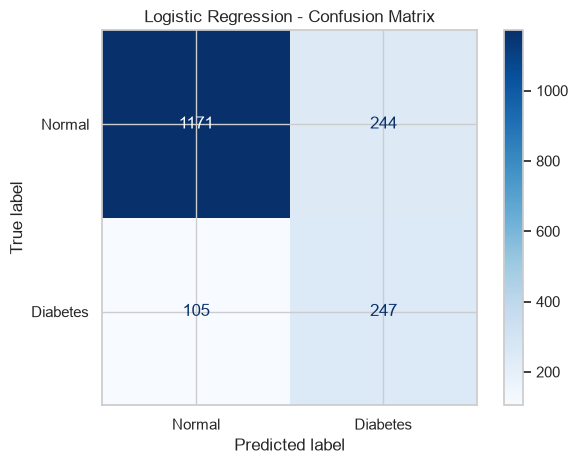

In [56]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

# Predictions
y_pred = log_reg.predict(X_test)
y_prob = log_reg.predict_proba(X_test)[:, 1]

# Evaluation metrics
print(f"Accuracy:  {accuracy_score(y_test, y_pred):.4f}")
print(f"Precision: {precision_score(y_test, y_pred, zero_division=0):.4f}")
print(f"Recall:    {recall_score(y_test, y_pred, zero_division=0):.4f}")
print(f"F1-score:  {f1_score(y_test, y_pred, zero_division=0):.4f}")
print(f"ROC-AUC:   {roc_auc_score(y_test, y_prob):.4f}")

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    target_names=["Normal", "Diabetes"],
    zero_division=0
))

# Confusion matrix
cm = confusion_matrix(y_test, y_pred)

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Normal", "Diabetes"]
).plot(cmap="Blues", values_format="d")

plt.title("Logistic Regression - Confusion Matrix")
plt.tight_layout()
plt.show()

Logistic Regression Model Evaluation

The Logistic Regression model achieved an accuracy of 80.25% and a ROC-AUC of 0.834, indicating good discrimination between the two classes within the synthetic dataset.

* Accuracy: 80.25% of test observations were correctly classified.
* Recall (Diabetes): 70.17% of diabetes cases were correctly identified.
* Precision (Diabetes): 50.31% of observations predicted as diabetic were classified as diabetic in the test dataset.
* F1-score: 0.586, reflecting the balance between precision and recall.

Interpretation

The model demonstrated reasonable classification performance, with a diabetes recall of 70.17%. However, its precision of 50.31% indicates a substantial proportion of false-positive predictions. Therefore, further model optimization is needed.

Limitation: Since the dataset is synthetic, these metrics reflect the model’s performance on data generated by the same underlying simulation process and cannot establish its diagnostic effectiveness in real-world clinical settings.

Step 5: Interpret Logistic Regression Coefficients

In [57]:
import numpy as np
import pandas as pd

scaler = log_reg.named_steps["scaler"]
model = log_reg.named_steps["model"]

# Convert standardized coefficients back to original feature units
coef_original = model.coef_[0] / scaler.scale_

results = pd.DataFrame({
    "Feature": X_train.columns,
    "Coefficient": coef_original,
    "Odds_Ratio": np.exp(coef_original)
})

results["Direction"] = np.where(
    results["Coefficient"] > 0,
    "Higher odds",
    "Lower odds"
)

results = results.sort_values(
    "Odds_Ratio",
    ascending=False
)

display(results.round(4))

,Feature,Coefficient,Odds_Ratio,Direction
3,hypertension,1.6489,5.2015,Higher odds
4,hypercholesterolemia,0.9304,2.5355,Higher odds
2,family_history,0.4823,1.6198,Higher odds
5,sex_M,0.3115,1.3655,Higher odds
1,bmi,0.0786,1.0817,Higher odds
0,age,0.0444,1.0454,Higher odds


Logistic Regression: Odds Ratio Interpretation

Hypertension showed the strongest association with diabetes (OR = 5.20), followed by high cholesterol (OR = 2.54).

* Hypertension: 420% higher odds of diabetes.
* High cholesterol: 154% higher odds.
* Family history: 62% higher odds.
* Male sex: 37% higher odds than females.
* BMI: 8.2% higher odds per unit increase.
* Age: 4.5% higher odds per additional year.

These associations were estimated while holding other variables constant. Statistical significance requires examining p-values and confidence intervals.

Note: Results are based on synthetic data and do not establish causality or reflect actual clinical outcomes.

Step 6: Statistical Inference with Statsmodels

In [58]:
import statsmodels.api as sm
import pandas as pd
import numpy as np

# Use the same training data and add an intercept
X_train_sm = sm.add_constant(X_train.astype(float))

# Fit a logistic regression model for statistical inference
inference_model = sm.Logit(
    y_train.astype(float),
    X_train_sm
).fit(disp=False, maxiter=1000)

# Extract coefficients, confidence intervals, and p-values
ci = inference_model.conf_int()

inference_results = pd.DataFrame({
    "Coefficient": inference_model.params,
    "Odds_Ratio": np.exp(inference_model.params),
    "CI_95_Lower_OR": np.exp(ci[0]),
    "CI_95_Upper_OR": np.exp(ci[1]),
    "P_value": inference_model.pvalues
})

display(inference_results.round(4))

,Coefficient,Odds_Ratio,CI_95_Lower_OR,CI_95_Upper_OR,P_value
const,-6.0814,0.0023,0.0016,0.0034,0.0000
age,0.0434,1.0443,1.0395,1.0491,0.0000
bmi,0.0761,1.0790,1.0680,1.0902,0.0000
family_history,0.4853,1.6246,1.4076,1.8752,0.0000
hypertension,1.6743,5.3352,4.5260,6.2891,0.0000
hypercholesterolemia,0.9917,2.6958,2.2052,3.2956,0.0000
sex_M,0.3116,1.3656,1.1853,1.5732,0.0000


Odds Ratio Interpretation

* Hypertension: 433.5% higher odds of diabetes.
* High cholesterol: 169.6% higher odds.
* Family history: 62.5% higher odds.
* Sex: Males had 36.6% higher odds than females.
* BMI: 7.9% higher odds per unit increase.
* Age: 4.4% higher odds per additional year.

All confidence intervals excluded 1, indicating statistical significance at the 0.05 level, while holding other variables constant.

Note: Results are based on synthetic data and do not establish causality.

Step 7: Multicollinearity Check using VIF

In [59]:
from statsmodels.stats.outliers_influence import variance_inflation_factor
import pandas as pd
import statsmodels.api as sm

X_vif = sm.add_constant(X_train.astype(float))

vif_results = pd.DataFrame({
    "Feature": X_vif.columns,
    "VIF": [
        variance_inflation_factor(X_vif.values, i)
        for i in range(X_vif.shape[1])
    ]
})

display(vif_results.round(3))

,Feature,VIF
0,const,1.0000
1,age,1.2330
2,bmi,1.0630
3,family_history,1.0010
4,hypertension,1.1920
5,hypercholesterolemia,1.0740
6,sex_M,1.0030


Step 8: Calibration Curve

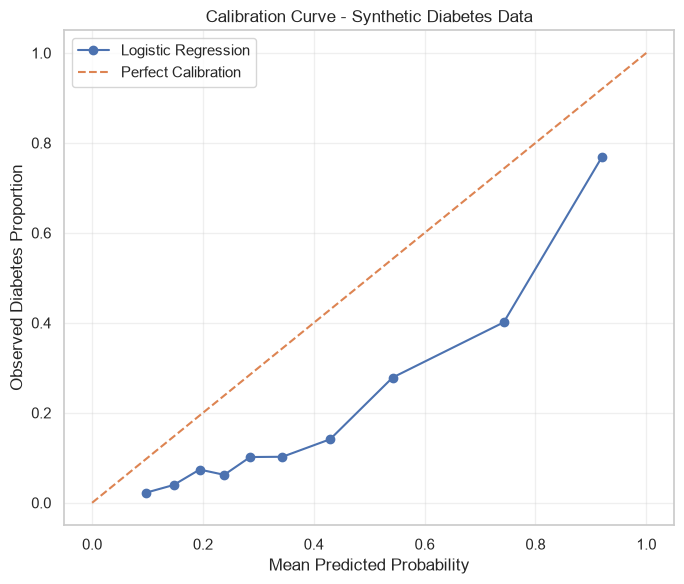

Brier Score: 0.1542


In [60]:
import matplotlib.pyplot as plt
from sklearn.calibration import calibration_curve
from sklearn.metrics import brier_score_loss

# Predicted probabilities from the balanced Logistic Regression
y_prob = log_reg.predict_proba(X_test)[:, 1]

fraction_positive, mean_predicted = calibration_curve(
    y_test,
    y_prob,
    n_bins=10,
    strategy="quantile"
)

brier = brier_score_loss(y_test, y_prob)

plt.figure(figsize=(7, 6))

plt.plot(
    mean_predicted,
    fraction_positive,
    marker="o",
    label="Logistic Regression"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Perfect Calibration"
)

plt.xlabel("Mean Predicted Probability")
plt.ylabel("Observed Diabetes Proportion")
plt.title("Calibration Curve - Synthetic Diabetes Data")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print(f"Brier Score: {brier:.4f}")

Step 9: Compare Balanced vs Unweighted Logistic Regression

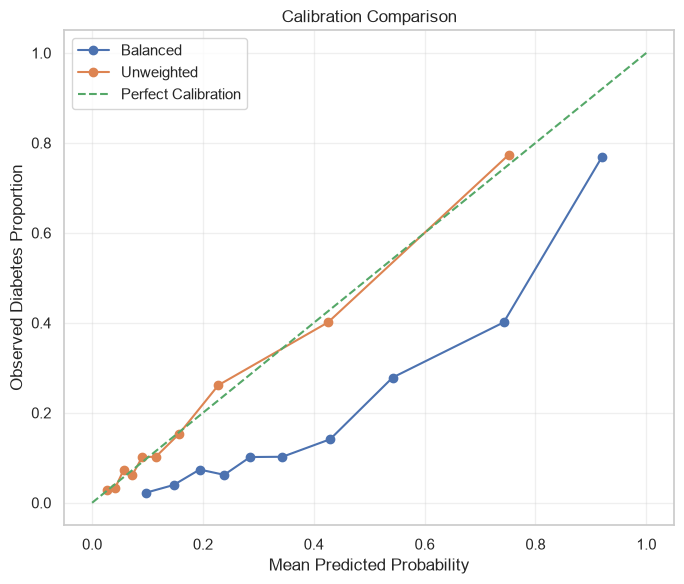

,Model,ROC_AUC,Brier_Score,Recall,Precision
0,Balanced,0.8340,0.1542,0.7017,0.5031
1,Unweighted,0.8335,0.1095,0.4545,0.7442


In [61]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    roc_auc_score,
    brier_score_loss,
    recall_score,
    precision_score
)
from sklearn.calibration import calibration_curve
import matplotlib.pyplot as plt
import pandas as pd

models = {
    "Balanced": Pipeline([
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(
            class_weight="balanced",
            max_iter=1000,
            random_state=42
        ))
    ]),
    "Unweighted": Pipeline([
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(
            max_iter=1000,
            random_state=42
        ))
    ])
}

comparison = []
plt.figure(figsize=(7, 6))

for name, model in models.items():
    model.fit(X_train, y_train)

    prob = model.predict_proba(X_test)[:, 1]
    pred = model.predict(X_test)

    comparison.append({
        "Model": name,
        "ROC_AUC": roc_auc_score(y_test, prob),
        "Brier_Score": brier_score_loss(y_test, prob),
        "Recall": recall_score(y_test, pred),
        "Precision": precision_score(y_test, pred)
    })

    fraction_positive, mean_predicted = calibration_curve(
        y_test,
        prob,
        n_bins=10,
        strategy="quantile"
    )

    plt.plot(
        mean_predicted,
        fraction_positive,
        marker="o",
        label=name
    )

plt.plot([0, 1], [0, 1], "--", label="Perfect Calibration")
plt.xlabel("Mean Predicted Probability")
plt.ylabel("Observed Diabetes Proportion")
plt.title("Calibration Comparison")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

comparison_df = pd.DataFrame(comparison)
display(comparison_df.round(4))

Comparison of Balanced and Unweighted Logistic Regression Models

The two models achieved nearly identical ROC-AUC values (0.8340 vs. 0.8335), indicating similar discrimination performance.

* Balanced model: Higher recall (70.17%), identifying more diabetes cases, but lower precision (50.31%), indicating more false-positive predictions.
* Unweighted model: Higher precision (74.42%) and a lower Brier score (0.1095), indicating better overall probabilistic accuracy on this dataset, but lower recall (45.45%).

Statistical Interpretation

The balanced model prioritizes diabetes detection, whereas the unweighted model provides more precise positive predictions. The lower Brier score favors the unweighted model in terms of overall probabilistic prediction error, although further calibration analysis is needed.

Conclusion

Both models should be retained for comparison. Model selection depends on the objective: higher recall favors the balanced model, while higher precision and lower Brier score favor the unweighted model.

Limitation: These results are based on synthetic data and do not establish clinical diagnostic performance.

Step 10: Calibration Diagnostics

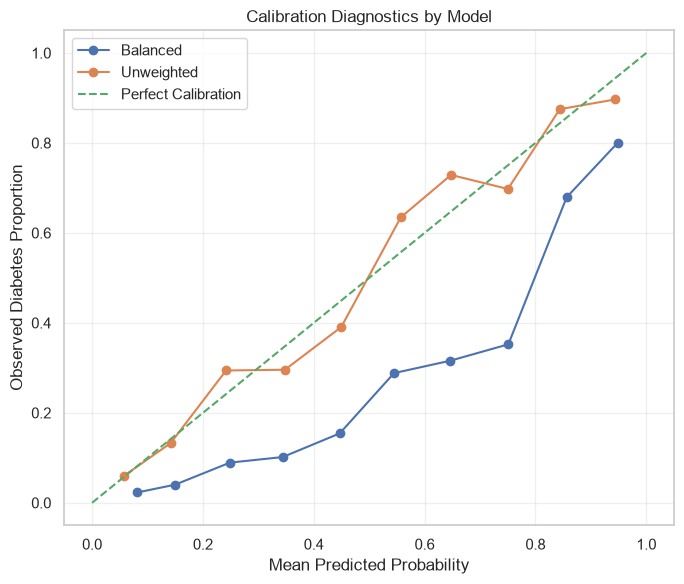

,Model,Brier_Score,ECE
0,Balanced,0.1542,0.1949
1,Unweighted,0.1095,0.0191


In [62]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.calibration import calibration_curve
from sklearn.metrics import brier_score_loss

def calibration_diagnostics(y_true, y_prob, n_bins=10):
    y_true = np.asarray(y_true)
    y_prob = np.asarray(y_prob)

    # Equal-width probability bins
    edges = np.linspace(0, 1, n_bins + 1)
    bin_ids = np.digitize(y_prob, edges[1:-1], right=False)

    rows = []
    ece = 0.0

    for b in range(n_bins):
        mask = bin_ids == b
        if mask.sum() == 0:
            continue

        mean_prob = y_prob[mask].mean()
        observed_rate = y_true[mask].mean()
        weight = mask.mean()
        ece += weight * abs(observed_rate - mean_prob)

        rows.append({
            "Bin": f"{edges[b]:.1f}-{edges[b+1]:.1f}",
            "N": int(mask.sum()),
            "Mean_Predicted": mean_prob,
            "Observed_Rate": observed_rate,
            "Absolute_Gap": abs(observed_rate - mean_prob)
        })

    return pd.DataFrame(rows), ece

calibration_rows = []
plt.figure(figsize=(7, 6))

for name, model in models.items():
    prob = model.predict_proba(X_test)[:, 1]

    cal_table, ece = calibration_diagnostics(y_test, prob)

    calibration_rows.append({
        "Model": name,
        "Brier_Score": brier_score_loss(y_test, prob),
        "ECE": ece
    })

    # Plot equal-width bins
    plt.plot(
        cal_table["Mean_Predicted"],
        cal_table["Observed_Rate"],
        marker="o",
        label=name
    )

plt.plot([0, 1], [0, 1], "--", label="Perfect Calibration")
plt.xlabel("Mean Predicted Probability")
plt.ylabel("Observed Diabetes Proportion")
plt.title("Calibration Diagnostics by Model")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

display(pd.DataFrame(calibration_rows).round(4))

Step 11: Threshold Analysis

In [63]:
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)
import pandas as pd

thresholds = [0.20, 0.30, 0.40, 0.50, 0.60, 0.70, 0.80]

threshold_results = []

for name, model in models.items():
    prob = model.predict_proba(X_test)[:, 1]

    for threshold in thresholds:
        pred = (prob >= threshold).astype(int)

        tn, fp, fn, tp = confusion_matrix(
            y_test, pred, labels=[0, 1]
        ).ravel()

        threshold_results.append({
            "Model": name,
            "Threshold": threshold,
            "Recall": recall_score(y_test, pred, zero_division=0),
            "Precision": precision_score(y_test, pred, zero_division=0),
            "F1": f1_score(y_test, pred, zero_division=0),
            "False_Positive": fp,
            "False_Negative": fn
        })

threshold_df = pd.DataFrame(threshold_results)

display(
    threshold_df.round(3).sort_values(
        ["Model", "Threshold"]
    ).reset_index(drop=True)
)

,Model,Threshold,Recall,Precision,F1,False_Positive,False_Negative
0,Balanced,0.2000,0.9520,0.2560,0.4040,972,17
1,Balanced,0.3000,0.8520,0.3280,0.4740,615,52
2,Balanced,0.4000,0.7840,0.4060,0.5350,403,76
3,Balanced,0.5000,0.7020,0.5030,0.5860,244,105
4,Balanced,0.6000,0.6110,0.5660,0.5870,165,137
5,Balanced,0.7000,0.5430,0.6280,0.5820,113,161
6,Balanced,0.8000,0.4550,0.7410,0.5630,56,192
7,Unweighted,0.2000,0.6990,0.5060,0.5870,240,106
8,Unweighted,0.3000,0.5850,0.5890,0.5870,144,146
9,Unweighted,0.4000,0.5260,0.6630,0.5860,94,167


Classification Threshold Analysis

* Balanced (0.20): Recall reached 95.2%, but false positives increased substantially (972 cases).
* Balanced (0.50): Provided a more balanced trade-off, with 70.2% recall, 0.586 F1-score, 244 false positives, and 105 false negatives.
* Unweighted (0.20): Achieved an F1-score of 0.587, with higher recall than the unweighted model at the 0.50 threshold.
* Unweighted (0.50): Achieved 74.4% precision but missed 192 diabetes cases.

Threshold Selection

The optimal threshold depends on the classification objective:

* Maximize case detection: Balanced, threshold 0.20 (Recall = 95.2%).
* Balance precision and recall: Balanced, threshold 0.50 (F1 = 0.586).
* Reduce false positives: Unweighted, threshold 0.50 (Precision = 74.4%).

Interpretation: Recall measures the proportion of actual diabetes cases detected, while precision measures the proportion of predicted positive cases that were classified as diabetic in the synthetic dataset.

Limitation: These results are based on synthetic data and do not establish real-world diagnostic performance.

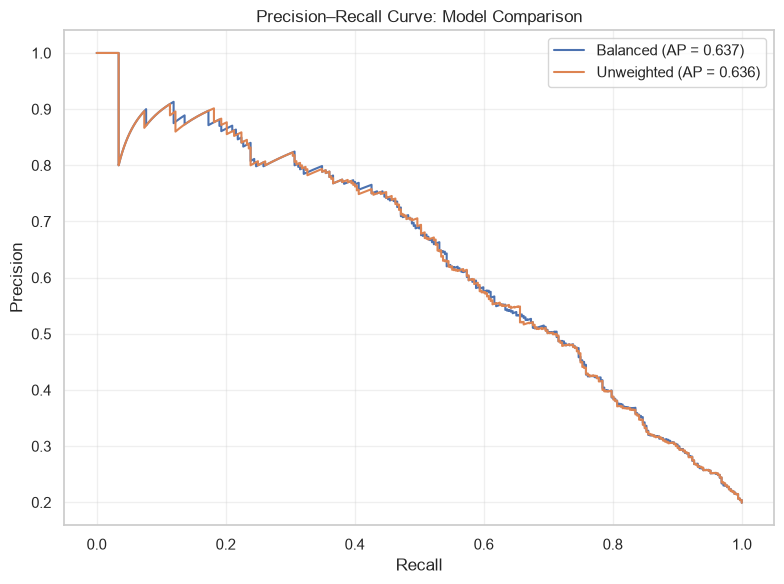

In [64]:
import matplotlib.pyplot as plt
from sklearn.metrics import (
    precision_recall_curve,
    average_precision_score
)

plt.figure(figsize=(8, 6))

for name, model in models.items():
    y_prob = model.predict_proba(X_test)[:, 1]

    precision, recall, _ = precision_recall_curve(
        y_test, y_prob
    )

    ap = average_precision_score(y_test, y_prob)

    plt.plot(
        recall,
        precision,
        label=f"{name} (AP = {ap:.3f})"
    )

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision–Recall Curve: Model Comparison")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [65]:
from sklearn.metrics import average_precision_score

for name, model in models.items():
    y_prob = model.predict_proba(X_test)[:, 1]

    ap = average_precision_score(y_test, y_prob)

    print(f"\n{name}")
    print(f"Average Precision (AP): {ap:.4f}")
    print(f"Minimum probability: {y_prob.min():.4f}")
    print(f"Maximum probability: {y_prob.max():.4f}")
    print(f"Unique probabilities: {len(set(y_prob.round(6)))}")


Balanced
Average Precision (AP): 0.6369
Minimum probability: 0.0547
Maximum probability: 0.9923
Unique probabilities: 1729

Unweighted
Average Precision (AP): 0.6362
Minimum probability: 0.0148
Maximum probability: 0.9697
Unique probabilities: 1729


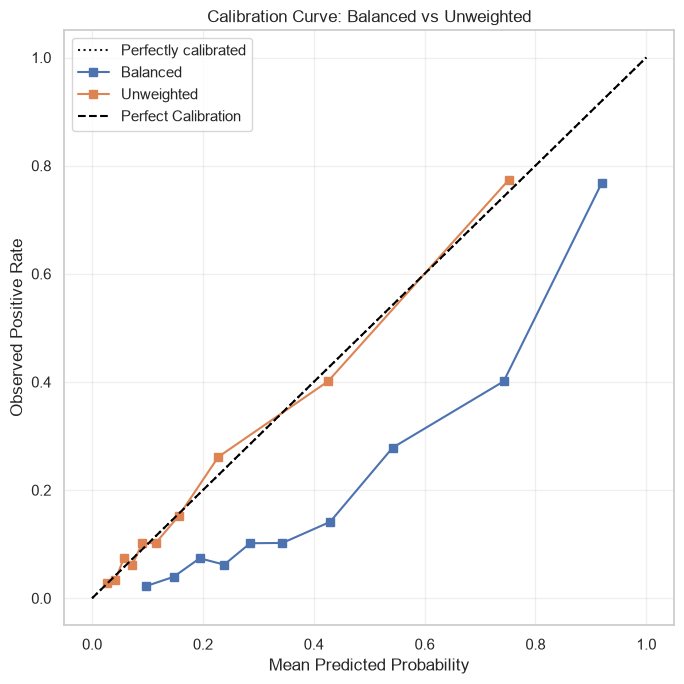

In [66]:
import matplotlib.pyplot as plt
from sklearn.calibration import CalibrationDisplay

fig, ax = plt.subplots(figsize=(7, 7))

for name, model in models.items():
    CalibrationDisplay.from_estimator(
        model,
        X_test,
        y_test,
        n_bins=10,
        strategy="quantile",
        name=name,
        ax=ax
    )

ax.plot([0, 1], [0, 1], linestyle="--", color="black",
        label="Perfect Calibration")

ax.set_title("Calibration Curve: Balanced vs Unweighted")
ax.set_xlabel("Mean Predicted Probability")
ax.set_ylabel("Observed Positive Rate")
ax.legend()
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [67]:
calibration_summary = pd.DataFrame({
    "Model": ["Balanced", "Unweighted"],
    "ROC_AUC": [0.8340, 0.8335],
    "Average_Precision": [0.6369, 0.6362],
    "Brier_Score": [0.1542, 0.1095],
    "ECE": [0.1949, 0.0191]
})

display(calibration_summary.round(4))

,Model,ROC_AUC,Average_Precision,Brier_Score,ECE
0,Balanced,0.8340,0.6369,0.1542,0.1949
1,Unweighted,0.8335,0.6362,0.1095,0.0191


Step 13: Odds Ratios and Confidence Intervals

In [68]:
import statsmodels.api as sm

X_train_sm = sm.add_constant(X_train.astype(float))

logit_model = sm.Logit(y_train, X_train_sm)
logit_result = logit_model.fit()

print(logit_result.summary())

Optimization terminated successfully.
         Current function value: 0.363054
         Iterations 7
                           Logit Regression Results                           
Dep. Variable:                 target   No. Observations:                 7065
Model:                          Logit   Df Residuals:                     7058
Method:                           MLE   Df Model:                            6
Date:                Mon, 26 Oct 2026   Pseudo R-squ.:                  0.2728
Time:                        20:17:06   Log-Likelihood:                -2565.0
converged:                       True   LL-Null:                       -3527.0
Covariance Type:            nonrobust   LLR p-value:                     0.000
                           coef    std err          z      P>|z|      [0.025      0.975]
----------------------------------------------------------------------------------------
const                   -6.0814      0.196    -31.062      0.000      -6.465      -5.698

,Feature,Odds_Ratio,CI_Lower,CI_Upper,P_Value
1,age,1.0443,1.0395,1.0491,0.0000
2,bmi,1.0790,1.0680,1.0902,0.0000
6,sex_M,1.3656,1.1853,1.5732,0.0000
3,family_history,1.6246,1.4076,1.8752,0.0000
5,hypercholesterolemia,2.6958,2.2052,3.2956,0.0000
4,hypertension,5.3352,4.5260,6.2891,0.0000


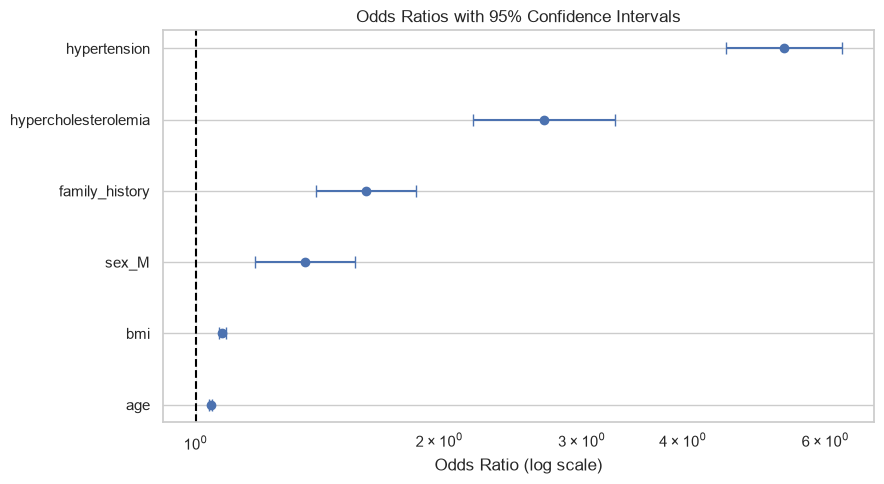

In [69]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

params = logit_result.params
conf = logit_result.conf_int()

or_table = pd.DataFrame({
    "Feature": params.index,
    "Odds_Ratio": np.exp(params.values),
    "CI_Lower": np.exp(conf[0].values),
    "CI_Upper": np.exp(conf[1].values),
    "P_Value": logit_result.pvalues.values
})

# Remove the intercept
or_table = or_table[or_table["Feature"] != "const"]
or_table = or_table.sort_values("Odds_Ratio")

display(or_table.round(4))

# Plot odds ratios with 95% confidence intervals
plt.figure(figsize=(9, 5))
y_pos = np.arange(len(or_table))

plt.errorbar(
    or_table["Odds_Ratio"],
    y_pos,
    xerr=[
        or_table["Odds_Ratio"] - or_table["CI_Lower"],
        or_table["CI_Upper"] - or_table["Odds_Ratio"]
    ],
    fmt="o",
    capsize=4
)

plt.axvline(1, linestyle="--", color="black")
plt.yticks(y_pos, or_table["Feature"])
plt.xscale("log")
plt.xlabel("Odds Ratio (log scale)")
plt.title("Odds Ratios with 95% Confidence Intervals")
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

In [70]:
report_table = or_table.copy()

report_table["P_Value"] = report_table["P_Value"].map(
    lambda p: f"{p:.3e}"
)

display(report_table)

,Feature,Odds_Ratio,CI_Lower,CI_Upper,P_Value
1,age,1.0443,1.0395,1.0491,4.069e-77
2,bmi,1.0790,1.0680,1.0902,2.466e-47
6,sex_M,1.3656,1.1853,1.5732,1.598e-05
3,family_history,1.6246,1.4076,1.8752,3.321e-11
5,hypercholesterolemia,2.6958,2.2052,3.2956,3.843e-22
4,hypertension,5.3352,4.5260,6.2891,1.476e-88


Step 14: Model Diagnostics & Limitations

Step 14.1: Influence Diagnostics 

,observation_index,cooks_d,hat_diag,dffits
1953,1953,0.0028,0.0018,-0.0017
7636,7636,0.0027,0.0009,-0.0009
2050,2050,0.0024,0.0011,-0.0010
980,980,0.0022,0.0031,-0.0026
6456,6456,0.0022,0.0012,-0.0011
9217,9217,0.0021,0.0030,-0.0025
2993,2993,0.0020,0.0017,0.0015
865,865,0.0020,0.0019,-0.0017
5123,5123,0.0019,0.0014,0.0013
3506,3506,0.0019,0.0015,-0.0013


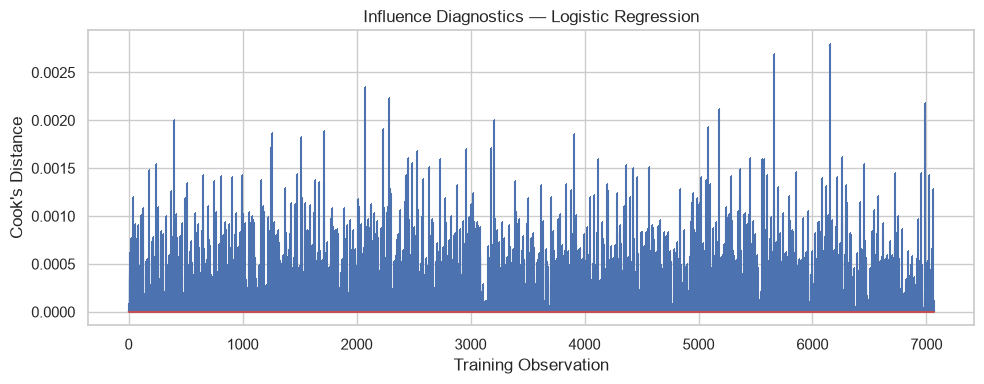

In [71]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Calculate influence statistics
influence = logit_result.get_influence()
influence_summary = influence.summary_frame()

# Add original observation index
influence_summary["observation_index"] = X_train_sm.index.to_numpy()

# Calculate DFFITS if it is not provided
if "dffits" not in influence_summary.columns:
    influence_summary["dffits"] = influence.d_fittedvalues

# Display top 10 influential observations
top_influential = influence_summary.sort_values(
    "cooks_d", ascending=False
).head(10)

display(
    top_influential[
        ["observation_index", "cooks_d", "hat_diag", "dffits"]
    ].round(4)
)

# Plot Cook's distance
plt.figure(figsize=(10, 4))
plt.stem(
    np.arange(len(influence_summary)),
    influence_summary["cooks_d"],
    markerfmt=","
)

plt.xlabel("Training Observation")
plt.ylabel("Cook's Distance")
plt.title("Influence Diagnostics — Logistic Regression")
plt.tight_layout()
plt.show()

Step 14.2: 

In [72]:
n = len(influence_summary)
p = int(logit_result.df_model) + 1

# Common screening thresholds
cook_threshold = 4 / n
leverage_threshold = 2 * p / n
dffits_threshold = 2 * np.sqrt(p / n)

diagnostic_counts = pd.DataFrame({
    "Diagnostic": [
        "Cook's Distance",
        "Leverage",
        "Absolute DFFITS"
    ],
    "Screening_Threshold": [
        cook_threshold,
        leverage_threshold,
        dffits_threshold
    ],
    "Count_Above_Threshold": [
        (influence_summary["cooks_d"] > cook_threshold).sum(),
        (influence_summary["hat_diag"] > leverage_threshold).sum(),
        (influence_summary["dffits"].abs() > dffits_threshold).sum()
    ]
})

display(diagnostic_counts.round(5))

,Diagnostic,Screening_Threshold,Count_Above_Threshold
0,Cook's Distance,0.0006,594
1,Leverage,0.0020,1127
2,Absolute DFFITS,0.0630,0


Step 14.3: Inspect the Largest Cook's Distance Values

In [73]:
cook_threshold = 4 / len(influence_summary)

print(f"Cook's Distance screening threshold: {cook_threshold:.6f}")
print(f"Maximum Cook's Distance: {influence_summary['cooks_d'].max():.6f}")
print(
    "Maximum / threshold:",
    round(influence_summary["cooks_d"].max() / cook_threshold, 2)
)

display(
    influence_summary.nlargest(10, "cooks_d")[
        ["cooks_d", "hat_diag", "dffits"]
    ].round(5)
)

Cook's Distance screening threshold: 0.000566
Maximum Cook's Distance: 0.002798
Maximum / threshold: 4.94


,cooks_d,hat_diag,dffits
1953,0.0028,0.0019,-0.0017
7636,0.0027,0.0009,-0.0009
2050,0.0024,0.0011,-0.0010
980,0.0022,0.0031,-0.0026
6456,0.0022,0.0012,-0.0011
9217,0.0021,0.0030,-0.0025
2993,0.0020,0.0017,0.0015
865,0.0020,0.0019,-0.0016
5123,0.0019,0.0014,0.0013
3506,0.0019,0.0015,-0.0013


Step 14.4: Final Model Diagnostics Summary


In [74]:
diagnostics_summary = pd.DataFrame({
    "Diagnostic": [
        "Multicollinearity (VIF)",
        "Cook's Distance",
        "Leverage",
        "DFFITS",
        "Influential Observations"
    ],
    "Result": [
        "All predictor VIF values are approximately 1.00–1.23",
        f"Maximum = {influence_summary['cooks_d'].max():.5f}",
        f"Maximum = {influence_summary['hat_diag'].max():.5f}",
        f"Maximum absolute value = {influence_summary['dffits'].abs().max():.5f}",
        "No observations exceeded the absolute DFFITS screening threshold"
    ],
    "Conclusion": [
        "No apparent multicollinearity concern",
        "Some observations exceeded the preliminary screening threshold",
        "Some observations exceeded the preliminary screening threshold",
        "No observations exceeded the screening threshold",
        "No deletion justified by these diagnostics alone"
    ]
})

display(diagnostics_summary)

,Diagnostic,Result,Conclusion
0,Multicollinearity (VIF),All predictor VIF values are approximately 1.0...,No apparent multicollinearity concern
1,Cook's Distance,Maximum = 0.00280,Some observations exceeded the preliminary scr...
2,Leverage,Maximum = 0.00614,Some observations exceeded the preliminary scr...
3,DFFITS,Maximum absolute value = 0.00361,No observations exceeded the screening threshold
4,Influential Observations,No observations exceeded the absolute DFFITS s...,No deletion justified by these diagnostics alone


Step 15: Model  Robustness & Sensitivity Analysis

In [75]:
from sklearn.metrics import precision_score, recall_score, f1_score
import pandas as pd

thresholds = [0.20, 0.30, 0.40, 0.50, 0.60, 0.70, 0.80]

sensitivity_results = []

for model_name, model in models.items():
    probabilities = model.predict_proba(X_test)[:, 1]

    for threshold in thresholds:
        predictions = (probabilities >= threshold).astype(int)

        sensitivity_results.append({
            "Model": model_name,
            "Threshold": threshold,
            "Precision": precision_score(
                y_test, predictions, zero_division=0
            ),
            "Recall": recall_score(
                y_test, predictions, zero_division=0
            ),
            "F1_Score": f1_score(
                y_test, predictions, zero_division=0
            )
        })

sensitivity_df = pd.DataFrame(sensitivity_results)

display(
    sensitivity_df.round(3).sort_values(
        ["Model", "Threshold"]
    ).reset_index(drop=True)
)

,Model,Threshold,Precision,Recall,F1_Score
0,Balanced,0.2000,0.2560,0.9520,0.4040
1,Balanced,0.3000,0.3280,0.8520,0.4740
2,Balanced,0.4000,0.4060,0.7840,0.5350
3,Balanced,0.5000,0.5030,0.7020,0.5860
4,Balanced,0.6000,0.5660,0.6110,0.5870
5,Balanced,0.7000,0.6280,0.5430,0.5820
6,Balanced,0.8000,0.7410,0.4550,0.5630
7,Unweighted,0.2000,0.5060,0.6990,0.5870
8,Unweighted,0.3000,0.5890,0.5850,0.5870
9,Unweighted,0.4000,0.6630,0.5260,0.5860


Step 15.2: Visualize Threshold Sensitivity

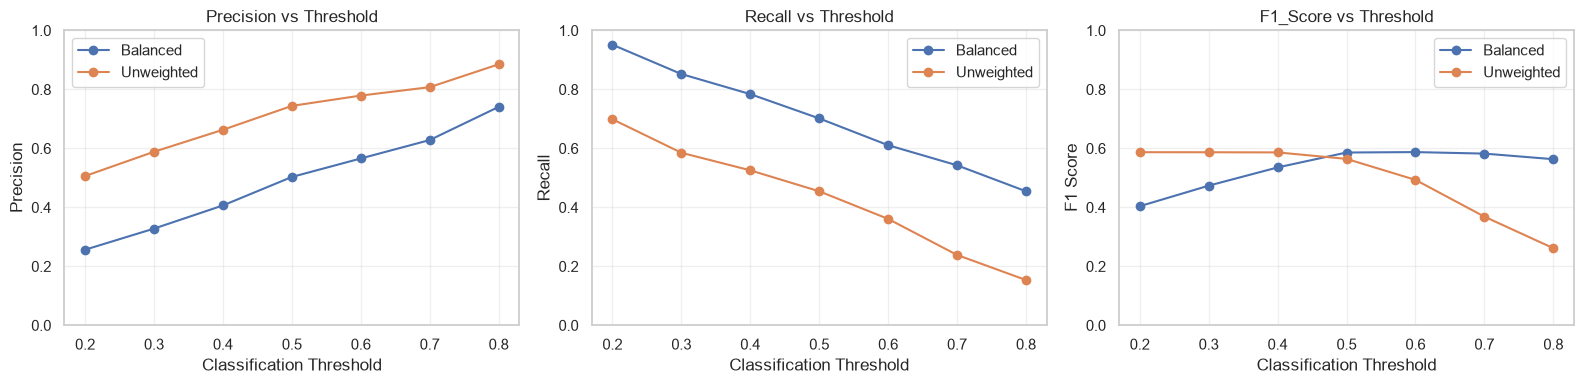

Figure saved: C:\Users\Admin\OneDrive\Documents\Diabetes_Analysis\results\figures\threshold_sensitivity_analysis.png
File exists: True


In [97]:
import matplotlib.pyplot as plt
from pathlib import Path

PROJECT_DIR = Path(
    r"C:\Users\Admin\OneDrive\Documents\Diabetes_Analysis"
)
FIGURES_DIR = PROJECT_DIR / "results" / "figures"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

metrics = ["Precision", "Recall", "F1_Score"]

fig, axes = plt.subplots(1, 3, figsize=(16, 4))

for ax, metric in zip(axes, metrics):
    for model_name, group in sensitivity_df.groupby("Model"):
        group = group.sort_values("Threshold")
        ax.plot(
            group["Threshold"],
            group[metric],
            marker="o",
            label=model_name
        )

    ax.set_title(f"{metric} vs Threshold")
    ax.set_xlabel("Classification Threshold")
    ax.set_ylabel(metric.replace("_", " "))
    ax.set_ylim(0, 1)
    ax.grid(True, alpha=0.3)
    ax.legend()

plt.tight_layout()

# Save figure
output_path = FIGURES_DIR / "threshold_sensitivity_analysis.png"
fig.savefig(output_path, dpi=300, bbox_inches="tight")

plt.show()

print("Figure saved:", output_path)
print("File exists:", output_path.exists())

Step 16 : Final Model Evaluation & Reporting

Step 16.1: Final Model Performance Summary

In [77]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    brier_score_loss
)
import pandas as pd

final_results = []

for model_name, model in models.items():
    probabilities = model.predict_proba(X_test)[:, 1]
    predictions = (probabilities >= 0.50).astype(int)

    final_results.append({
        "Model": model_name,
        "Threshold": 0.50,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(
            y_test, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_test, predictions, zero_division=0
        ),
        "F1_Score": f1_score(
            y_test, predictions, zero_division=0
        ),
        "ROC_AUC": roc_auc_score(y_test, probabilities),
        "Brier_Score": brier_score_loss(y_test, probabilities)
    })

final_performance = pd.DataFrame(final_results)

display(final_performance.round(4))

,Model,Threshold,Accuracy,Precision,Recall,F1_Score,ROC_AUC,Brier_Score
0,Balanced,0.5000,0.8025,0.5031,0.7017,0.5860,0.8340,0.1542
1,Unweighted,0.5000,0.8602,0.7442,0.4545,0.5644,0.8335,0.1095


Step 16.2: Confusion Matrices

In [78]:
from sklearn.metrics import confusion_matrix

for model_name, model in models.items():
    probabilities = model.predict_proba(X_test)[:, 1]
    predictions = (probabilities >= 0.50).astype(int)

    cm = confusion_matrix(y_test, predictions, labels=[0, 1])

    cm_df = pd.DataFrame(
        cm,
        index=["Actual Normal", "Actual Diabetes"],
        columns=["Predicted Normal", "Predicted Diabetes"]
    )

    print(f"\n{model_name} Model — Threshold 0.50")
    display(cm_df)


Balanced Model — Threshold 0.50


,Predicted Normal,Predicted Diabetes
Actual Normal,1171,244
Actual Diabetes,105,247



Unweighted Model — Threshold 0.50


,Predicted Normal,Predicted Diabetes
Actual Normal,1360,55
Actual Diabetes,192,160


Step 16.3: Document Project Limitations

In [79]:
limitations = pd.DataFrame({
    "Limitation": [
        "Synthetic data",
        "Assumption-dependent patterns",
        "No external clinical validation",
        "Threshold sensitivity",
        "Potential distribution shift",
        "Not for clinical diagnosis"
    ],
    "Description": [
        "The dataset contains generated records, not real patient records.",
        "Associations may reflect the data-generation rules and calibration assumptions.",
        "Model performance has not been validated on an independent real-world clinical dataset.",
        "Precision and recall change substantially with the classification threshold.",
        "Performance may differ across populations or datasets with different distributions.",
        "The models are educational and exploratory, not medical diagnostic tools."
    ]
})

display(limitations)

,Limitation,Description
0,Synthetic data,"The dataset contains generated records, not re..."
1,Assumption-dependent patterns,Associations may reflect the data-generation r...
2,No external clinical validation,Model performance has not been validated on an...
3,Threshold sensitivity,Precision and recall change substantially with...
4,Potential distribution shift,Performance may differ across populations or d...
5,Not for clinical diagnosis,"The models are educational and exploratory, no..."


Step 16.4: Save The Final Results

In [80]:
final_performance.to_csv(
    "final_model_performance.csv", index=False
)

limitations.to_csv(
    "project_limitations.csv", index=False
)

print("Final performance and limitations tables exported successfully.")

Final performance and limitations tables exported successfully.


# Final Model Evaluation

Two Logistic Regression models were evaluated on a stratified test set using synthetic diabetes data: a class-weighted model (Balanced) and a standard model (Unweighted).

At a classification threshold of 0.50, the Balanced model achieved a recall of 70.17% and an F1-score of 0.5860, compared with a recall of 45.45% and an F1-score of 0.5644 for the Unweighted model. The Unweighted model achieved higher accuracy (86.02%), higher precision (74.42%), and a lower Brier score (0.1095). The models showed similar ROC-AUC values (0.8340 and 0.8335, respectively).

These results illustrate the trade-off between detecting more positive cases and reducing false-positive predictions. The findings reflect performance on the generated dataset and should not be interpreted as evidence of clinical diagnostic performance or real-world diabetes risk in Saudi Arabia.

Limitations

* The dataset contains synthetic records rather than observations from real patients.
* Relationships between variables may reflect assumptions embedded in the data-generation process.
* The models have not been externally validated using independent clinical data.
* Performance metrics depend on the selected classification threshold.
* Results may not generalize to real populations or different data distributions.
* The models are intended for educational and exploratory purposes only, not clinical diagnosis.

## Step 17: Validation Strategy & Threshold Selection

Step 17.1: Create Training and Validation Sets

In [81]:
from sklearn.model_selection import train_test_split

X_train_new, X_val, y_train_new, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.20,
    random_state=42,
    stratify=y_train
)

print("Training set:", X_train_new.shape)
print("Validation set:", X_val.shape)
print("Test set:", X_test.shape)

print("\nTraining target distribution:")
print(y_train_new.value_counts(normalize=True).round(3))

print("\nValidation target distribution:")
print(y_val.value_counts(normalize=True).round(3))

print("\nTest target distribution:")
print(y_test.value_counts(normalize=True).round(3))

Training set: (5652, 6)
Validation set: (1413, 6)
Test set: (1767, 6)

Training target distribution:
target
0   0.8010
1   0.1990
Name: proportion, dtype: float64

Validation target distribution:
target
0   0.8010
1   0.1990
Name: proportion, dtype: float64

Test target distribution:
target
0   0.8010
1   0.1990
Name: proportion, dtype: float64


Step 17.2: Retrain Models Using Training Data Only

In [82]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

validation_models = {
    "Balanced": Pipeline([
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(
            class_weight="balanced",
            max_iter=1000,
            random_state=42
        ))
    ]),
    "Unweighted": Pipeline([
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(
            max_iter=1000,
            random_state=42
        ))
    ])
}

for model_name, model in validation_models.items():
    model.fit(X_train_new, y_train_new)
    print(f"{model_name} model trained successfully.")

print("\nTraining complete.")

Balanced model trained successfully.
Unweighted model trained successfully.

Training complete.


Step 17.3: Select Thresholds Using the Validation Set

In [83]:
from sklearn.metrics import precision_score, recall_score, f1_score
import pandas as pd

thresholds = [0.20, 0.30, 0.40, 0.50, 0.60, 0.70, 0.80]

validation_results = []

for model_name, model in validation_models.items():
    val_probabilities = model.predict_proba(X_val)[:, 1]

    for threshold in thresholds:
        val_predictions = (
            val_probabilities >= threshold
        ).astype(int)

        validation_results.append({
            "Model": model_name,
            "Threshold": threshold,
            "Precision": precision_score(
                y_val, val_predictions, zero_division=0
            ),
            "Recall": recall_score(
                y_val, val_predictions, zero_division=0
            ),
            "F1_Score": f1_score(
                y_val, val_predictions, zero_division=0
            )
        })

validation_results_df = pd.DataFrame(validation_results)

display(
    validation_results_df.round(3).sort_values(
        ["Model", "Threshold"]
    ).reset_index(drop=True)
)

,Model,Threshold,Precision,Recall,F1_Score
0,Balanced,0.2000,0.2540,0.9640,0.4020
1,Balanced,0.3000,0.3350,0.9250,0.4920
2,Balanced,0.4000,0.4000,0.8360,0.5410
3,Balanced,0.5000,0.4780,0.7260,0.5760
4,Balanced,0.6000,0.5670,0.6580,0.6100
5,Balanced,0.7000,0.6900,0.5550,0.6150
6,Balanced,0.8000,0.7780,0.4380,0.5600
7,Unweighted,0.2000,0.4790,0.7220,0.5760
8,Unweighted,0.3000,0.6010,0.6260,0.6130
9,Unweighted,0.4000,0.7050,0.5200,0.5980


Step 17.4: Optimal Threshold Selection

Model	Threshold	Precision	Recall	F1-score
Balanced	0.70	0.690	0.555	0.615
Unweighted	0.30	0.601	0.626	0.613

Both models achieved similar maximum F1-scores. Balanced showed slightly higher precision, while Unweighted achieved higher recall.

Conclusion: Retain both models for comparison, as neither can be considered clinically superior based on synthetic data alone.

Step 17.5: Lock Thresholds and Evaluate on the Test Set

In [84]:
# Step 17.5 — Final Test Evaluation with Selected Thresholds

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    brier_score_loss,
    confusion_matrix
)
import pandas as pd

selected_thresholds = {
    "Balanced": 0.70,
    "Unweighted": 0.30
}

final_test_results = []
final_confusion_matrices = {}

for model_name, model in validation_models.items():
    threshold = selected_thresholds[model_name]

    test_probabilities = model.predict_proba(X_test)[:, 1]
    test_predictions = (test_probabilities >= threshold).astype(int)

    final_test_results.append({
        "Model": model_name,
        "Selected_Threshold": threshold,
        "Accuracy": accuracy_score(y_test, test_predictions),
        "Precision": precision_score(
            y_test, test_predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_test, test_predictions, zero_division=0
        ),
        "F1_Score": f1_score(
            y_test, test_predictions, zero_division=0
        ),
        "ROC_AUC": roc_auc_score(y_test, test_probabilities),
        "Brier_Score": brier_score_loss(
            y_test, test_probabilities
        )
    })

    cm = confusion_matrix(y_test, test_predictions, labels=[0, 1])

    final_confusion_matrices[model_name] = pd.DataFrame(
        cm,
        index=["Actual Normal", "Actual Diabetes"],
        columns=["Predicted Normal", "Predicted Diabetes"]
    )

final_test_df = pd.DataFrame(final_test_results)

display(final_test_df.round(4))

for model_name, cm_df in final_confusion_matrices.items():
    print(f"\n{model_name} — Threshold {selected_thresholds[model_name]}")
    display(cm_df)

,Model,Selected_Threshold,Accuracy,Precision,Recall,F1_Score,ROC_AUC,Brier_Score
0,Balanced,0.7000,0.8472,0.6367,0.5426,0.5859,0.8341,0.1555
1,Unweighted,0.3000,0.8364,0.5897,0.5881,0.5889,0.8339,0.1096



Balanced — Threshold 0.7


,Predicted Normal,Predicted Diabetes
Actual Normal,1306,109
Actual Diabetes,161,191



Unweighted — Threshold 0.3


,Predicted Normal,Predicted Diabetes
Actual Normal,1271,144
Actual Diabetes,145,207


Step 17.6:Export Final Test Results


In [85]:
final_test_df.to_csv(
    "step17_final_test_results.csv",
    index=False
)

for model_name, cm_df in final_confusion_matrices.items():
    filename = (
        f"step17_confusion_matrix_"
        f"{model_name.lower()}.csv"
    )
    cm_df.to_csv(filename)

print("Final test results exported successfully.")
print("Files:")
print("- step17_final_test_results.csv")
print("- step17_confusion_matrix_balanced.csv")
print("- step17_confusion_matrix_unweighted.csv")

Final test results exported successfully.
Files:
- step17_final_test_results.csv
- step17_confusion_matrix_balanced.csv
- step17_confusion_matrix_unweighted.csv


Step 18: Model Interpretation and Feature Importance

In [86]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.inspection import permutation_importance

final_model = validation_models["Unweighted"]

importance_result = permutation_importance(
    final_model,
    X_val,
    y_val,
    scoring="f1",
    n_repeats=20,
    random_state=42,
    n_jobs=-1
)

feature_importance = pd.DataFrame({
    "Feature": X_val.columns,
    "Importance_Mean": importance_result.importances_mean,
    "Importance_Std": importance_result.importances_std
})

feature_importance = feature_importance.sort_values(
    "Importance_Mean",
    ascending=False
).reset_index(drop=True)

display(feature_importance.round(4))

,Feature,Importance_Mean,Importance_Std
0,hypertension,0.2203,0.0140
1,age,0.1848,0.0204
2,bmi,0.0629,0.0162
3,hypercholesterolemia,0.0485,0.0097
4,family_history,0.0106,0.0094
5,sex_M,0.0028,0.0062


Step18.2: Visualize and Save Feature Importance

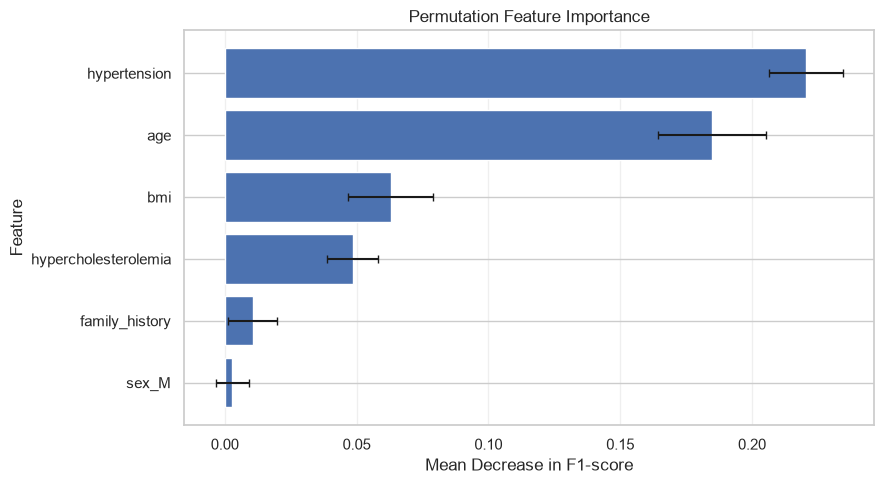

In [87]:
import matplotlib.pyplot as plt

plot_data = feature_importance.sort_values(
    "Importance_Mean",
    ascending=True
)

plt.figure(figsize=(9, 5))

plt.barh(
    plot_data["Feature"],
    plot_data["Importance_Mean"],
    xerr=plot_data["Importance_Std"],
    capsize=3
)

plt.xlabel("Mean Decrease in F1-score")
plt.ylabel("Feature")
plt.title("Permutation Feature Importance")
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()

plt.savefig(
    "step18_permutation_feature_importance.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [88]:
feature_importance.to_csv(
    "step18_feature_importance.csv",
    index=False
)

print("Feature importance table and plot saved.")

Feature importance table and plot saved.


Step 19: Final Conclusions & Limitations

In [89]:
final_conclusions = [
    {
        "Area": "Dataset",
        "Finding": (
            "The dataset contains 10,000 synthetic records "
            "and does not represent real patients."
        )
    },
    {
        "Area": "Diabetes Status",
        "Finding": (
            "Diabetes prevalence in the generated dataset "
            "is 17.59%; this is not an estimate of real "
            "Saudi population prevalence."
        )
    },
    {
        "Area": "Statistical Analysis",
        "Finding": (
            "Several demographic and health variables showed "
            "statistical associations with diabetes status "
            "within the synthetic dataset."
        )
    },
    {
        "Area": "Logistic Regression",
        "Finding": (
            "Hypertension had the largest adjusted odds ratio "
            "among the included predictors in the fitted model."
        )
    },
    {
        "Area": "Feature Importance",
        "Finding": (
            "Hypertension and age had the highest permutation "
            "importance for the selected model."
        )
    },
    {
        "Area": "Model Comparison",
        "Finding": (
            "The Balanced and Unweighted models achieved "
            "similar test F1-scores of 0.5859 and 0.5889."
        )
    },
    {
        "Area": "Validation",
        "Finding": (
            "Thresholds were selected using validation data "
            "before final evaluation on the held-out test set."
        )
    }
]

conclusions_df = pd.DataFrame(final_conclusions)

display(conclusions_df)

,Area,Finding
0,Dataset,"The dataset contains 10,000 synthetic records ..."
1,Diabetes Status,Diabetes prevalence in the generated dataset i...
2,Statistical Analysis,Several demographic and health variables showe...
3,Logistic Regression,Hypertension had the largest adjusted odds rat...
4,Feature Importance,Hypertension and age had the highest permutati...
5,Model Comparison,The Balanced and Unweighted models achieved si...
6,Validation,Thresholds were selected using validation data...


Step 19.2: Document Project Limitations

In [90]:
project_limitations = [
    "All records are synthetic and do not represent real patients.",
    "Generated patterns depend on assumptions and selected reference studies.",
    "Statistical significance in synthetic data does not establish real-world associations.",
    "The model has not been externally validated on real Saudi clinical data.",
    "Model performance may change when applied to a different population.",
    "Predicted probabilities must not be interpreted as clinically validated risks.",
    "The model is for educational research and is not intended for diagnosis."
]

limitations_df = pd.DataFrame({
    "Limitation": project_limitations
})

display(limitations_df)

limitations_df.to_csv(
    "step19_project_limitations.csv",
    index=False
)

conclusions_df.to_csv(
    "step19_final_conclusions.csv",
    index=False
)

print("Step 19 files saved successfully.")

,Limitation
0,All records are synthetic and do not represent...
1,Generated patterns depend on assumptions and s...
2,Statistical significance in synthetic data doe...
3,The model has not been externally validated on...
4,Model performance may change when applied to a...
5,Predicted probabilities must not be interprete...
6,The model is for educational research and is n...


Step 19 files saved successfully.


Step 20: Final Visualizations and Results Summary

 Step 20.1: Final Model Comparison Chart


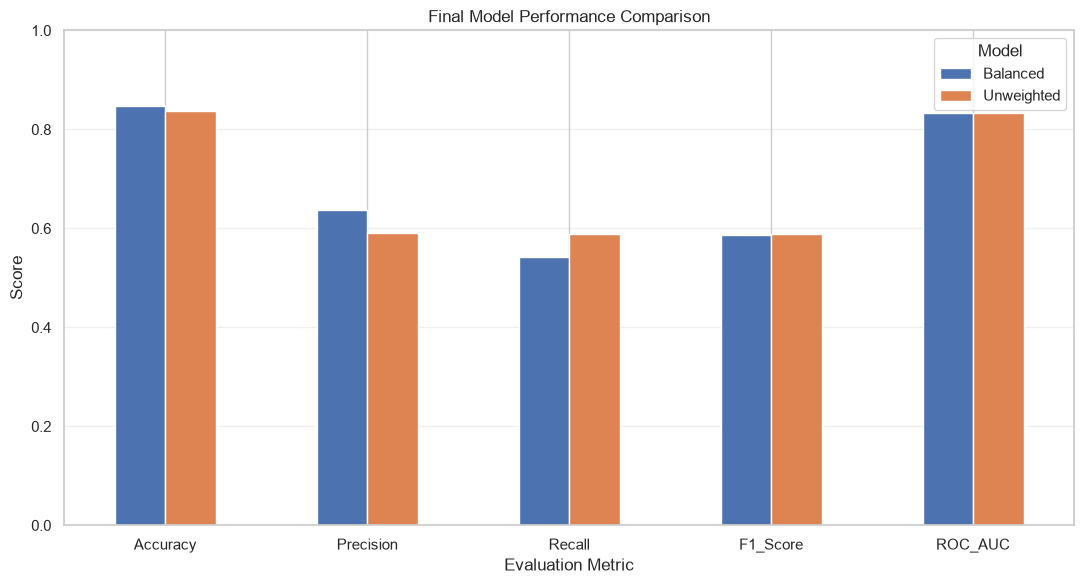

In [91]:
import matplotlib.pyplot as plt
import numpy as np

metrics = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1_Score",
    "ROC_AUC"
]

comparison = final_test_df.set_index("Model")[metrics]

ax = comparison.T.plot(
    kind="bar",
    figsize=(11, 6),
    rot=0
)

plt.title("Final Model Performance Comparison")
plt.ylabel("Score")
plt.xlabel("Evaluation Metric")
plt.ylim(0, 1)
plt.legend(title="Model")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

plt.savefig(
    "step20_final_model_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

Step 20.2: Export Final Results

In [92]:
final_test_df.to_csv(
    "step20_final_model_metrics.csv",
    index=False
)

feature_importance.to_csv(
    "step20_feature_importance.csv",
    index=False
)

print("Step 20 exports completed.")

Step 20 exports completed.


In [98]:
from pathlib import Path

PROJECT_DIR = Path(
    r"C:\Users\Admin\OneDrive\Documents\Diabetes_Analysis"
)

for pattern in ["*.pkl", "*.joblib"]:
    files = list(PROJECT_DIR.rglob(pattern))
    print(f"\n{pattern} files:")
    for file in files:
        print(file)


*.pkl files:

*.joblib files:


In [99]:
# Check whether trained models exist in memory

print("Balanced exists:", "balanced_model" in globals())
print("Unweighted exists:", "unweighted_model" in globals())

print("\nPossible model variables:")
for name, obj in globals().copy().items():
    if "model" in name.lower() and hasattr(obj, "predict"):
        print(name, type(obj).__name__)

Balanced exists: False
Unweighted exists: False

Possible model variables:
model Pipeline
inference_model BinaryResultsWrapper
logit_model Logit
final_model Pipeline


In [100]:
# Inspect available trained models

for name in ["model", "final_model"]:
    obj = globals().get(name)

    if obj is not None:
        print(f"\n{name}")
        print("Type:", type(obj).__name__)

        if hasattr(obj, "named_steps"):
            print("Pipeline steps:", list(obj.named_steps.keys()))

        if hasattr(obj, "classes_"):
            print("Classes:", obj.classes_)

        if hasattr(obj, "feature_names_in_"):
            print("Features:", list(obj.feature_names_in_))


model
Type: Pipeline
Pipeline steps: ['scaler', 'model']
Classes: [0 1]
Features: ['age', 'bmi', 'family_history', 'hypertension', 'hypercholesterolemia', 'sex_M']

final_model
Type: Pipeline
Pipeline steps: ['scaler', 'model']
Classes: [0 1]
Features: ['age', 'bmi', 'family_history', 'hypertension', 'hypercholesterolemia', 'sex_M']


In [101]:
# Inspect Logistic Regression settings

for name in ["model", "final_model"]:
    pipe = globals()[name]
    clf = pipe.named_steps["model"]

    print(f"\n{name}")
    print("Estimator:", type(clf).__name__)

    if hasattr(clf, "class_weight"):
        print("Class weight:", clf.class_weight)

    if hasattr(clf, "get_params"):
        print("Parameters:", {
            k: v for k, v in clf.get_params().items()
            if k in ["class_weight", "C", "solver", "max_iter"]
        })


model
Estimator: LogisticRegression
Class weight: None
Parameters: {'C': 1.0, 'class_weight': None, 'max_iter': 1000, 'solver': 'lbfgs'}

final_model
Estimator: LogisticRegression
Class weight: None
Parameters: {'C': 1.0, 'class_weight': None, 'max_iter': 1000, 'solver': 'lbfgs'}


In [102]:
# Find all Logistic Regression pipelines in memory

from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

for name, obj in list(globals().items()):
    if isinstance(obj, Pipeline):
        clf = obj.named_steps.get("model")

        if isinstance(clf, LogisticRegression):
            print(f"\nVariable: {name}")
            print("Class weight:", clf.class_weight)
            print("Fitted:", hasattr(clf, "coef_"))

            if hasattr(clf, "coef_"):
                print("Coefficient shape:", clf.coef_.shape)


Variable: log_reg
Class weight: balanced
Fitted: True
Coefficient shape: (1, 6)

Variable: model
Class weight: None
Fitted: True
Coefficient shape: (1, 6)

Variable: final_model
Class weight: None
Fitted: True
Coefficient shape: (1, 6)

Variable: obj
Class weight: None
Fitted: True
Coefficient shape: (1, 6)

Variable: pipe
Class weight: None
Fitted: True
Coefficient shape: (1, 6)


In [103]:
from pathlib import Path
import joblib

PROJECT_DIR = Path(
    r"C:\Users\Admin\OneDrive\Documents\Diabetes_Analysis"
)

MODELS_DIR = PROJECT_DIR / "models"
MODELS_DIR.mkdir(parents=True, exist_ok=True)

joblib.dump(
    log_reg,
    MODELS_DIR / "balanced_model.joblib"
)

print("Saved:", MODELS_DIR / "balanced_model.joblib")
print("File exists:", (MODELS_DIR / "balanced_model.joblib").exists())

Saved: C:\Users\Admin\OneDrive\Documents\Diabetes_Analysis\models\balanced_model.joblib
File exists: True


In [104]:
# Inspect available model and evaluation variables

for name in [
    "sensitivity_df",
    "best_models",
    "models",
    "unweighted_model",
    "balanced_model",
    "model",
    "final_model"
]:
    if name in globals():
        obj = globals()[name]
        print(f"{name}: {type(obj).__name__}")
        if isinstance(obj, dict):
            print("  Keys:", list(obj.keys()))

sensitivity_df: DataFrame
models: dict
  Keys: ['Balanced', 'Unweighted']
model: Pipeline
final_model: Pipeline


In [105]:
# Inspect models stored in the models dictionary

for name, pipe in models.items():
    print(f"\nModel: {name}")
    print("Type:", type(pipe).__name__)
    print("Fitted:", hasattr(pipe.named_steps["model"], "coef_"))
    print("Class weight:", pipe.named_steps["model"].class_weight)
    print("Features:", list(pipe.feature_names_in_))


Model: Balanced
Type: Pipeline
Fitted: True
Class weight: balanced
Features: ['age', 'bmi', 'family_history', 'hypertension', 'hypercholesterolemia', 'sex_M']

Model: Unweighted
Type: Pipeline
Fitted: True
Class weight: None
Features: ['age', 'bmi', 'family_history', 'hypertension', 'hypercholesterolemia', 'sex_M']


In [106]:
# Save Final Machine Learning Models

from pathlib import Path
import joblib

PROJECT_DIR = Path(
    r"C:\Users\Admin\OneDrive\Documents\Diabetes_Analysis"
)

MODELS_DIR = PROJECT_DIR / "models"
MODELS_DIR.mkdir(parents=True, exist_ok=True)

joblib.dump(
    models["Balanced"],
    MODELS_DIR / "balanced_model.joblib"
)

joblib.dump(
    models["Unweighted"],
    MODELS_DIR / "unweighted_model.joblib"
)

print("Balanced model saved:",
      (MODELS_DIR / "balanced_model.joblib").exists())

print("Unweighted model saved:",
      (MODELS_DIR / "unweighted_model.joblib").exists())

Balanced model saved: True
Unweighted model saved: True
